# Predicting Frequent Mental Distress from Lifestyle and Social Factors
### Traditional Machine Learning vs Deep Learning — BRFSS 2024

**Author:** Nazira Umucyo

**Problem:** Frequent mental distress means having 14 or more days of poor mental health in the past 30 days. This notebook tests whether we can predict it from everyday factors such as exercise, income, employment, and physical health. The aim is a screening aid that can help point people toward support, not a diagnosis tool.

**Data:** Behavioral Risk Factor Surveillance System (BRFSS) 2024, a yearly health survey of over 400,000 US adults run by the CDC.

**Approach:** Compare traditional machine learning models (scikit-learn) with deep learning models (TensorFlow/Keras), then evaluate them with learning curves, confusion matrices, ROC-AUC, and precision/recall.

## 1. Setup

This section imports the libraries used throughout the notebook and fixes the random seeds. Setting seeds means the data splits, model initialisation, and training give the same results every time the notebook runs, so the experiments can be reproduced.

Main libraries:
- **pandas / NumPy**: loading and cleaning the data
- **Matplotlib / Seaborn**: plots (class balance, learning curves, confusion matrices, ROC curves)
- **scikit-learn**: traditional ML models, preprocessing, and evaluation metrics
- **TensorFlow / Keras**: deep learning models and the `tf.data` input pipeline

In [3]:
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import tensorflow as tf

warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

pd.set_option("display.max_columns", 50)
sns.set_style("whitegrid")

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("tensorflow:", tf.__version__)

pandas: 2.2.3
numpy: 2.1.3
scikit-learn: 1.6.1
tensorflow: 2.21.0


## 2. Data Loading

The dataset is the **2024 BRFSS annual survey data** published by the US Centers for Disease Control and Prevention (CDC) on its open-data portal: https://www.cdc.gov/brfss/annual_data/annual_2024.html

Each row is one adult who answered the survey, and each column is one survey question. Answers are stored as numeric codes; the meaning of each code is listed in the official 2024 BRFSS codebook.

The raw file is downloaded directly from the CDC website in SAS Transport (`.XPT`) format and read with pandas. It is not stored in the GitHub repository. A zipped copy is kept in the project's Google Drive folder.

In [6]:
DATA_URL = "https://www.cdc.gov/brfss/annual_data/2024/files/LLCP2024XPT.zip"

!wget -nc -q --show-progress {DATA_URL}
!unzip -o -q LLCP2024XPT.zip
!ls -lh

total 1.1G
-rw-r--r-- 1 root root 1.1G Aug 21  2025 'LLCP2024.XPT '
-rw-r--r-- 1 root root  80M Aug 21  2025  LLCP2024XPT.zip
drwxr-xr-x 1 root root 4.0K Oct  2 13:50  sample_data


In [7]:
DATA_FILE = "LLCP2024.XPT "

df = pd.read_sas(DATA_FILE, format="xport", encoding="latin-1")

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (457670, 301)


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,PVTRESD1,COLGHOUS,STATERE1,CELPHON1,LADULT1,NUMADULT,RESPSLC1,LANDSEX3,SAFETIME,CTELNUM1,CELLFON5,CADULT1,CELLSEX3,PVTRESD3,CCLGHOUS,...,_VIRCOL2,_SBONTI2,_CRCREC3,_SMOKER3,_RFSMOK3,_CURECI3,LCSLAST_,LCSNUMC_,_LCSAGE,_LCSYSMK,_PACKDAY,_PACKYRS,_LCSYQTS,_LCSSMKG,_LCSELIG,_LCSCTSN,_LCSPSTF,DRNKANY6,DROCDY4_,_RFBING6,_DRNKWK3,_RFDRHV9,_FLSHOT7,_PNEUMO3,_AIDTST4
0,1.0,2.0,02282024,02,28,2024,1100.0,2024000001,2.024000e+09,1.0,1.0,NaN,1.0,2.0,1.0,1.0,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,4.0,1.0,1.0,NaN,NaN,2.0,NaN,NaN,NaN,NaN,6.0,2.0,NaN,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,2.0,2.0
1,1.0,2.0,02212024,02,21,2024,1100.0,2024000002,2.024000e+09,1.0,1.0,NaN,1.0,2.0,1.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,3.0,1.0,1.0,27.0,20.0,2.0,2.0,100.0,2.0,53.0,5.0,2.0,4.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0
2,1.0,2.0,02212024,02,21,2024,1100.0,2024000003,2.024000e+09,1.0,1.0,NaN,1.0,2.0,1.0,3.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.0,3.0,3.0,1.0,2.0,1.0,NaN,15.0,2.0,45.0,75.0,34.0,NaN,1.0,1.0,4.0,2.0,1.0,1.000000e+02,2.0,1.400000e+03,1.0,NaN,NaN,2.0
3,1.0,2.0,02282024,02,28,2024,1100.0,2024000004,2.024000e+09,1.0,1.0,NaN,1.0,2.0,1.0,1.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,4.0,1.0,1.0,NaN,NaN,3.0,NaN,NaN,NaN,NaN,6.0,2.0,NaN,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0
4,1.0,2.0,02212024,02,21,2024,1100.0,2024000005,2.024000e+09,1.0,1.0,NaN,1.0,2.0,1.0,3.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.0,3.0,3.0,4.0,1.0,1.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,6.0,2.0,3.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,NaN,NaN,2.0


## 3. Selecting the Target and Features

The raw file has 301 columns (the CDC lists 345, but some questions were removed from the 2024 public release). Most columns are survey admin fields (dates, phone type, state codes) or optional modules that only some states asked. We keep only the target and 14 features chosen because previous research links them to mental distress.

**Target:** `_MENT14D`, a CDC-calculated grouping of poor mental-health days in the past 30 days (1 = none, 2 = 1–13 days, 3 = 14+ days, 9 = unknown). We turn it into a binary label: **1 = frequent mental distress (14+ days)**, 0 = otherwise.

**Features, grouped by theme:**
- **Demographics:** age group (`_AGEG5YR`), sex (`_SEX`), marital status (`MARITAL`)
- **Socioeconomic:** education (`_EDUCAG`), income (`_INCOMG1`), employment (`EMPLOY1`), could not afford a doctor (`MEDCOST1`)
- **Lifestyle:** exercise (`EXERANY2`), smoking (`_SMOKER3`), heavy drinking (`_RFDRHV9`)
- **Physical health:** BMI (`_BMI5`), general health (`GENHLTH`), poor physical-health days (`PHYSHLTH`), diabetes (`DIABETE4`)

**Note on sleep:** sleep is strongly linked to mental health in the research, but the sleep question was not asked in the 2024 survey, so it could not be included.

**Leakage check:** `ADDEPEV3` ("ever told you have a depressive disorder") is kept aside for one experiment only. It is so close to the target that it could make the model look better than it really is.

In [8]:
TARGET_RAW = "_MENT14D"

FEATURES = ["_AGEG5YR", "_SEX", "MARITAL",
            "_EDUCAG", "_INCOMG1", "EMPLOY1", "MEDCOST1",
            "EXERANY2", "_SMOKER3", "_RFDRHV9",
            "_BMI5", "GENHLTH", "PHYSHLTH", "DIABETE4"]

LEAKAGE_COL = "ADDEPEV3"

cols = [TARGET_RAW] + FEATURES + [LEAKAGE_COL]

missing = [c for c in cols if c not in df.columns]
print("Columns not found:", missing)

data = df[cols].copy()
print("Rows, columns:", data.shape)
data.head()

Columns not found: []
Rows, columns: (457670, 16)


,_MENT14D,_AGEG5YR,_SEX,MARITAL,_EDUCAG,_INCOMG1,EMPLOY1,MEDCOST1,EXERANY2,_SMOKER3,_RFDRHV9,_BMI5,GENHLTH,PHYSHLTH,DIABETE4,ADDEPEV3
0,1.0,12.0,2.0,3.0,2.0,9.0,7.0,2.0,1.0,4.0,1.0,2249.0,3.0,2.0,3.0,2.0
1,1.0,13.0,1.0,1.0,4.0,7.0,7.0,2.0,1.0,3.0,1.0,2583.0,1.0,88.0,3.0,2.0
2,1.0,8.0,1.0,6.0,3.0,9.0,1.0,1.0,1.0,1.0,1.0,2253.0,2.0,30.0,3.0,2.0
3,1.0,13.0,1.0,1.0,4.0,4.0,7.0,2.0,1.0,4.0,1.0,2509.0,1.0,88.0,3.0,2.0
4,1.0,6.0,1.0,5.0,3.0,2.0,8.0,2.0,2.0,4.0,1.0,1977.0,3.0,88.0,3.0,2.0


## 4. Data Cleaning

BRFSS stores answers as numeric codes, and some codes are not real answers. Before modelling, these are cleaned as follows:

- **"Don't know / Refused / Not sure"** codes (7, 9, 77, 99, and 14 for age) are not real answers, so they are set to missing (`NaN`).
- **"None" in day counts:** in `PHYSHLTH`, the code 88 means "zero days", so it is changed to 0.
- **BMI:** `_BMI5` is stored as BMI × 100 (e.g. 2450 = 24.5), so it is divided by 100.
- **Tiny values:** when pandas reads SAS files, zeros sometimes appear as tiny numbers like `5.4e-79`. These are set back to 0.
- **Target:** rows where `_MENT14D` is 9 (unknown) are removed, since we cannot train on rows without a label. The rest are turned into a binary label: 1 if the person reported 14+ poor mental-health days, 0 otherwise.

The remaining missing values in the features are handled later, inside the modelling pipeline, so the same steps apply to the training and test data without information leaking between them.

In [9]:
MISSING_CODES = {
    "_AGEG5YR": [14],
    "MARITAL":  [9],
    "_EDUCAG":  [9],
    "_INCOMG1": [9],
    "EMPLOY1":  [9],
    "MEDCOST1": [7, 9],
    "EXERANY2": [7, 9],
    "_SMOKER3": [9],
    "_RFDRHV9": [9],
    "GENHLTH":  [7, 9],
    "PHYSHLTH": [77, 99],
    "DIABETE4": [7, 9],
    "ADDEPEV3": [7, 9],
}

def clean_brfss(raw):
    d = raw.copy()

    # SAS zeros read as tiny numbers (e.g. 5.4e-79) -> 0
    d = d.mask(d.abs() < 1e-10, 0)

    # "Don't know / Refused" codes -> missing
    for col, codes in MISSING_CODES.items():
        d[col] = d[col].replace(codes, np.nan)

    # 88 = "none" -> 0 days
    d["PHYSHLTH"] = d["PHYSHLTH"].replace(88, 0)

    # BMI is stored x100
    d["_BMI5"] = d["_BMI5"] / 100

    # keep rows with a known target, then make it binary
    d = d[d["_MENT14D"].isin([1, 2, 3])].copy()
    d["FMD"] = (d["_MENT14D"] == 3).astype(int)
    d = d.drop(columns="_MENT14D")

    return d

clean = clean_brfss(data)

print("Rows before:", len(data))
print("Rows after: ", len(clean))
print("Rows dropped (unknown target):", len(data) - len(clean))
print()
print("Target counts:")
print(clean["FMD"].value_counts())
print()
print("Target share (%):")
print((clean["FMD"].value_counts(normalize=True) * 100).round(2))
print()
print("Missing values per column (%):")
print((clean.isna().mean() * 100).round(2).sort_values(ascending=False))

Rows before: 457670
Rows after:  449514
Rows dropped (unknown target): 8156

Target counts:
FMD
0    387199
1     62315
Name: count, dtype: int64

Target share (%):
FMD
0    86.14
1    13.86
Name: proportion, dtype: float64

Missing values per column (%):
_INCOMG1    18.72
_RFDRHV9    10.05
_BMI5        9.24
_SMOKER3     6.91
PHYSHLTH     1.92
_AGEG5YR     1.76
EMPLOY1      1.76
MARITAL      0.88
ADDEPEV3     0.50
_EDUCAG      0.47
MEDCOST1     0.31
EXERANY2     0.24
GENHLTH      0.24
DIABETE4     0.20
_SEX         0.00
FMD          0.00
dtype: float64


### Cleaning results

After cleaning, **449,514 rows** remain. Only 8,156 rows (1.8%) were removed because the target was unknown.

**Class imbalance:** 13.86% of respondents report frequent mental distress (FMD = 1) and 86.14% do not (about a 1:6 ratio). A model that always predicts "no distress" would reach 86% accuracy while being useless, so accuracy alone is misleading here. Models are therefore compared mainly on **recall, precision, F1-score, and ROC-AUC** for the FMD = 1 class, and class weights are used during training so mistakes on the minority class count more.

**Missing values:** most features have under 7% missing. Income has the most (18.7%), which is common in surveys because many people refuse to answer income questions. Since not answering may itself carry information, an extra feature indicating whether income was missing is added during feature engineering and tested in the experiments.

## 5. Exploratory Data Analysis (EDA)

Before building models, we look at how each feature relates to frequent mental distress. For each feature, the chart shows the **percentage of people with FMD = 1 in each answer group**. If the percentage changes a lot across groups (for example, much higher among people who are unable to work), the feature is likely to be useful for prediction.

This also checks whether the patterns in the data agree with previous research, and highlights the age group 18–24 (code 1 in `_AGEG5YR`), which is the focus of this project.

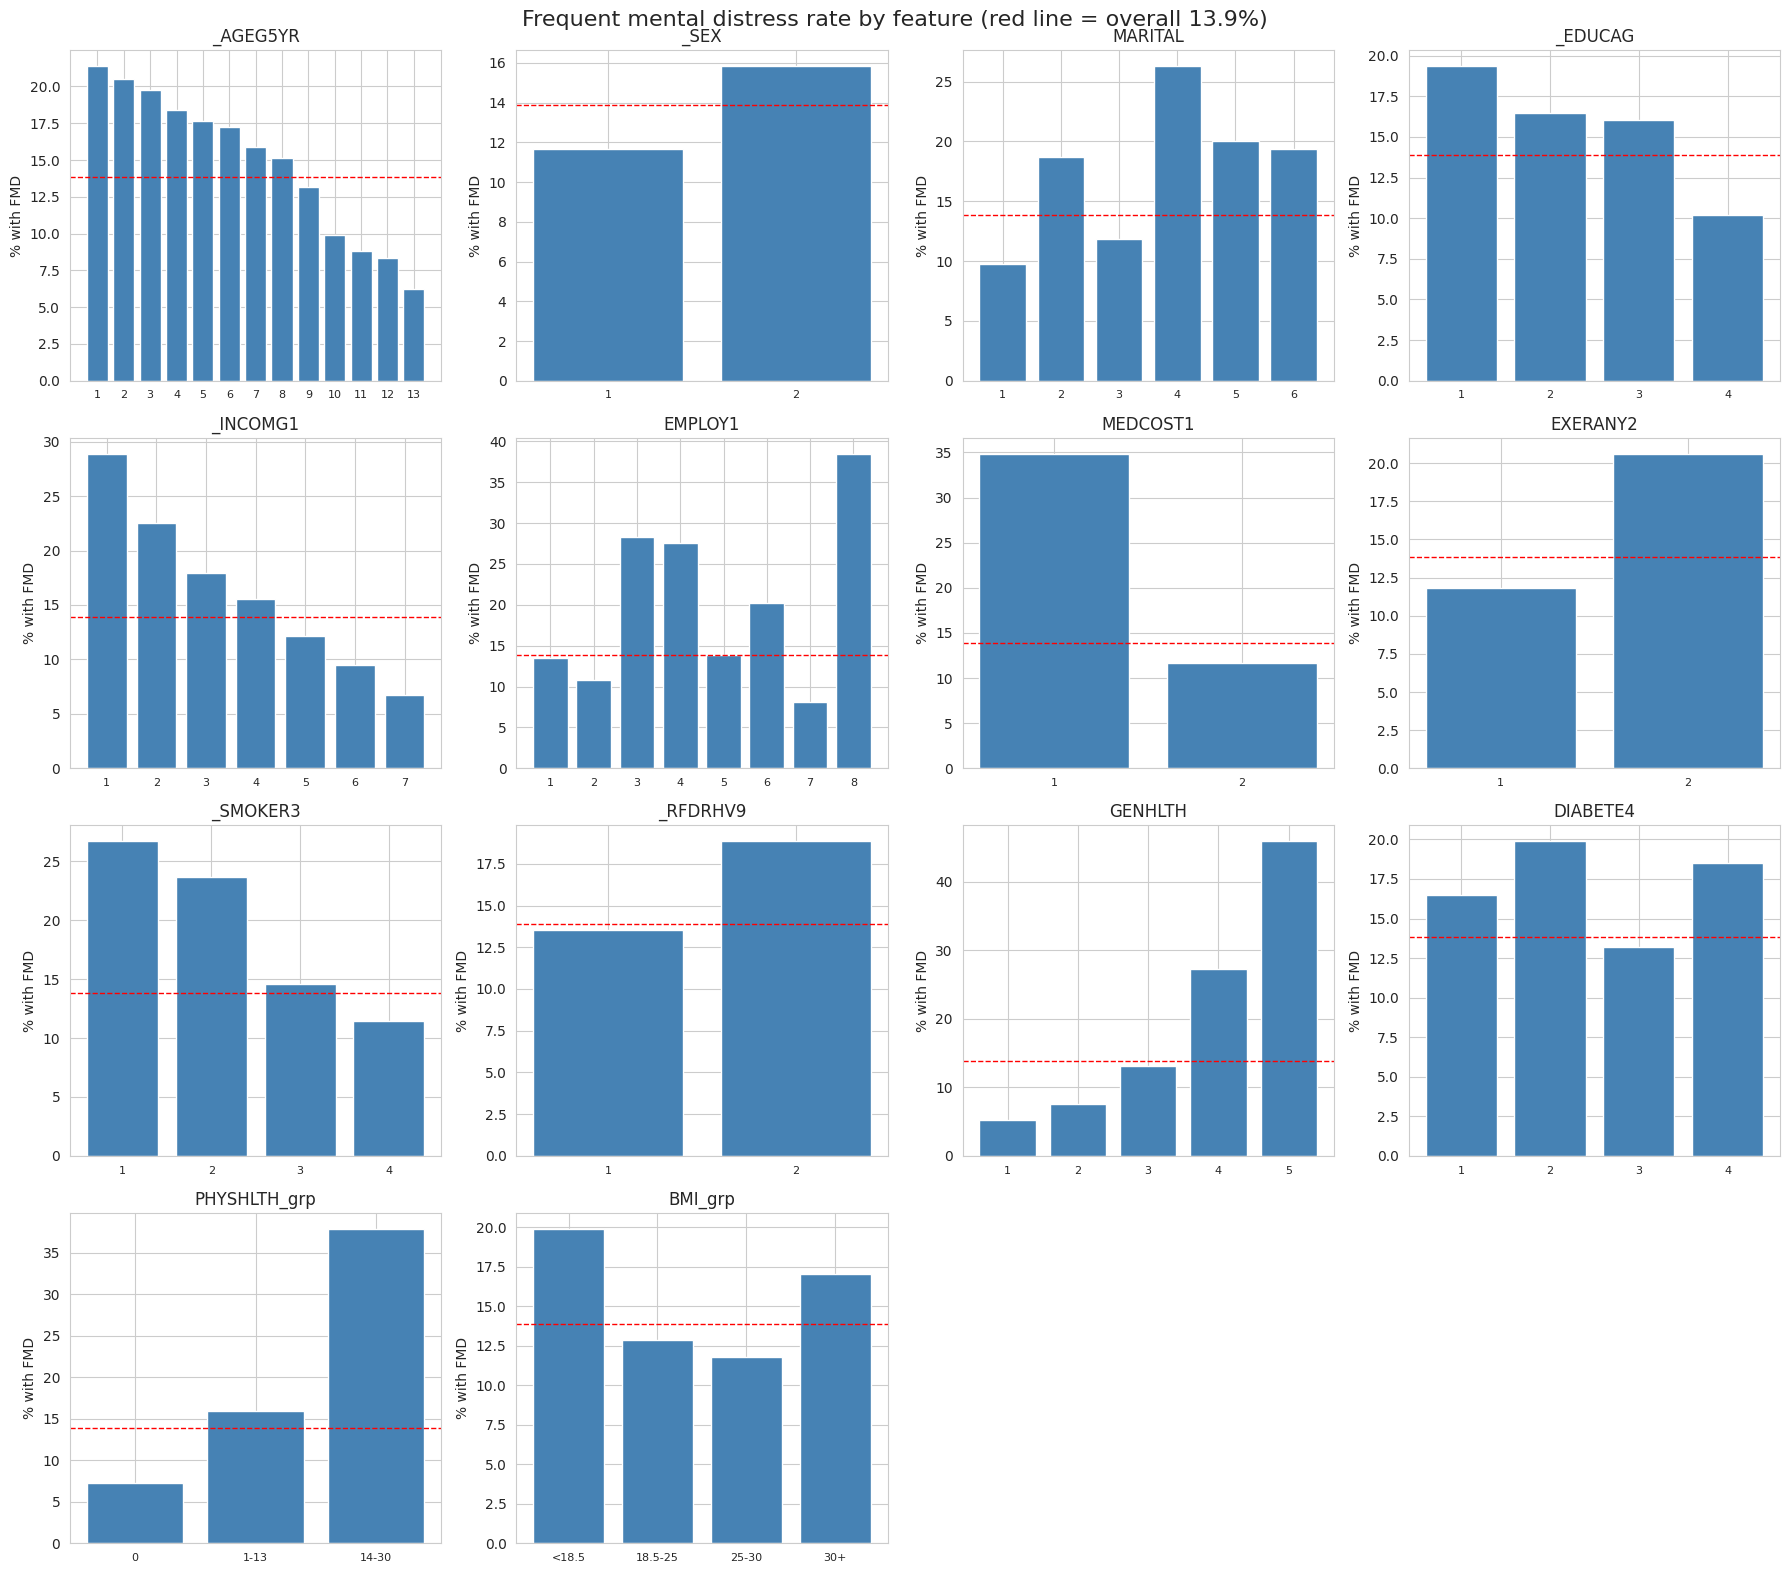

FMD rate (%) by age group code (1 = 18-24):
_AGEG5YR
1.0     21.4
2.0     20.5
3.0     19.7
4.0     18.4
5.0     17.6
6.0     17.2
7.0     15.9
8.0     15.2
9.0     13.1
10.0     9.9
11.0     8.8
12.0     8.3
13.0     6.3
Name: FMD, dtype: float64


In [10]:
os.makedirs("figures", exist_ok=True)

plot_df = clean.copy()
plot_df["PHYSHLTH_grp"] = pd.cut(plot_df["PHYSHLTH"], bins=[-1, 0, 13, 30],
                                 labels=["0", "1-13", "14-30"])
plot_df["BMI_grp"] = pd.cut(plot_df["_BMI5"], bins=[0, 18.5, 25, 30, 100],
                            labels=["<18.5", "18.5-25", "25-30", "30+"])

PLOT_COLS = ["_AGEG5YR", "_SEX", "MARITAL", "_EDUCAG", "_INCOMG1", "EMPLOY1",
             "MEDCOST1", "EXERANY2", "_SMOKER3", "_RFDRHV9", "GENHLTH",
             "DIABETE4", "PHYSHLTH_grp", "BMI_grp"]

overall_rate = clean["FMD"].mean() * 100

def label(v):
    return str(int(v)) if isinstance(v, float) else str(v)

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()

for ax, col in zip(axes, PLOT_COLS):
    rates = plot_df.groupby(col, observed=True)["FMD"].mean() * 100
    ax.bar([label(v) for v in rates.index], rates.values, color="steelblue")
    ax.axhline(overall_rate, color="red", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_ylabel("% with FMD")
    ax.tick_params(axis="x", labelsize=8)

for ax in axes[len(PLOT_COLS):]:
    ax.axis("off")

fig.suptitle(f"Frequent mental distress rate by feature (red line = overall {overall_rate:.1f}%)",
             fontsize=16)
plt.tight_layout()
plt.savefig("figures/fmd_rate_by_feature.png", dpi=150, bbox_inches="tight")
plt.show()

age_rates = (plot_df.groupby("_AGEG5YR")["FMD"].mean() * 100).round(1)
print("FMD rate (%) by age group code (1 = 18-24):")
print(age_rates)

### EDA findings

**Age:** young adults aged 18–24 have the highest FMD rate (21.4%), about 1.5 times the overall rate of 13.9%. The rate falls steadily with age to 6.3% among people aged 80+. Students also have a high rate (20.1%). This supports the project's focus on young people.

**Strongest relationships:** self-rated general health shows the largest gap (5% for "excellent" vs 46% for "poor"), followed by poor physical-health days (7% for none vs 38% for 14–30 days), employment ("unable to work" 38%, unemployed about 28%), and being unable to afford a doctor (35% vs 12%). Income shows a steady gradient from 29% in the lowest group to 7% in the highest. Self-rated health may partly reflect mental state as well, so its strength should be interpreted with care.

**Moderate relationships:** daily smoking (27% vs 11% for never smokers), no exercise (21% vs 12%), being separated or divorced, lower education, female sex, and heavy drinking are all linked to higher FMD rates.

**Implications for preprocessing:**
- `EMPLOY1`, `MARITAL`, and `DIABETE4` are categories with no natural order (their rates go up and down across codes), so they are **one-hot encoded**. Ordered features (age, education, income, smoking, general health) are kept as numbers.
- BMI has a **U-shaped** relationship with FMD: both underweight (20%) and obese (17%) groups are higher than normal weight (13%). A linear model cannot capture this from raw BMI, so BMI categories are added as an engineered feature.

## 6. Feature Engineering and Data Splitting

### Engineered features
Two features are added, both motivated by the EDA:
- **`INCOME_MISSING`** (1 = income not reported, 0 = reported). Income has the most missing values (18.7%), and not answering may itself carry information about a person's situation.
- **`BMI_CAT`** (underweight / normal / overweight / obese, using WHO cut-offs). BMI has a U-shaped relationship with FMD, which a linear model cannot learn from the raw value.

These features are created row by row from each person's own answers, so creating them before the split does not leak information between sets.

### Train / validation / test split
The data is split into **70% training, 15% validation, and 15% test**, using **stratified sampling** so each set keeps the same 13.9% FMD rate.
- **Training set:** used to fit the models.
- **Validation set:** used to compare experiments, tune hyperparameters, and stop deep learning training early.
- **Test set:** used only once at the end to report final performance, so the final results are not biased by tuning choices.

Steps that learn from the data (filling missing values, scaling, encoding) are fitted **on the training set only** and then applied to the validation and test sets.

In [11]:
from sklearn.model_selection import train_test_split

def add_features(d):
    d = d.copy()
    d["INCOME_MISSING"] = d["_INCOMG1"].isna().astype(int)
    d["BMI_CAT"] = pd.cut(d["_BMI5"], bins=[0, 18.5, 25, 30, np.inf],
                          labels=[1, 2, 3, 4], right=False).astype(float)
    return d

feat = add_features(clean)

X = feat.drop(columns="FMD")
y = feat["FMD"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

for name, ys in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<11} rows: {len(ys):>7,}   FMD rate: {ys.mean() * 100:.2f}%")

print()
print("FMD rate (%) by INCOME_MISSING (training set):")
print((y_train.groupby(X_train["INCOME_MISSING"]).mean() * 100).round(2))

Train       rows: 314,659   FMD rate: 13.86%
Validation  rows:  67,427   FMD rate: 13.86%
Test        rows:  67,428   FMD rate: 13.86%

FMD rate (%) by INCOME_MISSING (training set):
INCOME_MISSING
0    14.05
1    13.04
Name: FMD, dtype: float64


### Split results

The data was split into 314,659 training, 67,427 validation, and 67,428 test rows. Stratification kept the FMD rate at 13.86% in all three sets.

People who did not report their income had an FMD rate of 13.0%, compared with 14.1% for those who did. This difference is small, so the idea that skipping the income question signals higher risk is only weakly supported. `INCOME_MISSING` is kept for now and tested in an experiment with and without it.

## 7. Preprocessing Pipeline

Features are split into two groups and handled differently:

**Numeric and ordered features:** age group, education, income, general health, smoking status, poor physical-health days, BMI, and the yes/no features (sex, could not afford a doctor, exercise, heavy drinking, income missing).
- Missing values are filled with the **median** of the training set. The median is used instead of the mean because it is not pulled by extreme values.
- Values are then **standardised** (mean 0, standard deviation 1). This matters for logistic regression and neural networks, which train poorly when features are on very different scales (e.g. BMI around 28 vs. a yes/no code of 1 or 2).

**Unordered categories:** employment, marital status, diabetes, and BMI category.
- Missing values are filled with the **most frequent** category.
- Each category is then **one-hot encoded** (turned into separate 0/1 columns), so the model does not wrongly treat the codes as amounts.

Both steps are combined in a scikit-learn `ColumnTransformer`. It is **fitted on the training set only** and then applied to the validation and test sets, so no information from those sets leaks into training. The same fitted preprocessor is reused for both the traditional ML models and the deep learning models, so both paradigms see identical inputs.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

NUM_COLS = ["_AGEG5YR", "_EDUCAG", "_INCOMG1", "GENHLTH", "_SMOKER3",
            "PHYSHLTH", "_BMI5",
            "_SEX", "MEDCOST1", "EXERANY2", "_RFDRHV9", "INCOME_MISSING"]

CAT_COLS = ["EMPLOY1", "MARITAL", "DIABETE4", "BMI_CAT"]

def make_preprocessor(num_cols, cat_cols):
    num_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    cat_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols),
    ])

preprocessor = make_preprocessor(NUM_COLS, CAT_COLS)

X_train_p = preprocessor.fit_transform(X_train).astype(np.float32)
X_val_p   = preprocessor.transform(X_val).astype(np.float32)
X_test_p  = preprocessor.transform(X_test).astype(np.float32)

feature_names = preprocessor.get_feature_names_out()

print("Train shape:", X_train_p.shape)
print("Val shape:  ", X_val_p.shape)
print("Test shape: ", X_test_p.shape)
print("Missing values left in train:", np.isnan(X_train_p).sum())
print()
print("Final features:")
print(list(feature_names))

Train shape: (314659, 34)
Val shape:   (67427, 34)
Test shape:  (67428, 34)
Missing values left in train: 0

Final features:
['num___AGEG5YR', 'num___EDUCAG', 'num___INCOMG1', 'num__GENHLTH', 'num___SMOKER3', 'num__PHYSHLTH', 'num___BMI5', 'num___SEX', 'num__MEDCOST1', 'num__EXERANY2', 'num___RFDRHV9', 'num__INCOME_MISSING', 'cat__EMPLOY1_1.0', 'cat__EMPLOY1_2.0', 'cat__EMPLOY1_3.0', 'cat__EMPLOY1_4.0', 'cat__EMPLOY1_5.0', 'cat__EMPLOY1_6.0', 'cat__EMPLOY1_7.0', 'cat__EMPLOY1_8.0', 'cat__MARITAL_1.0', 'cat__MARITAL_2.0', 'cat__MARITAL_3.0', 'cat__MARITAL_4.0', 'cat__MARITAL_5.0', 'cat__MARITAL_6.0', 'cat__DIABETE4_1.0', 'cat__DIABETE4_2.0', 'cat__DIABETE4_3.0', 'cat__DIABETE4_4.0', 'cat__BMI_CAT_1.0', 'cat__BMI_CAT_2.0', 'cat__BMI_CAT_3.0', 'cat__BMI_CAT_4.0']


## 8. Evaluation Setup and Experiment Tracking

Every model is evaluated on the **validation set** with the same function, so results are directly comparable. Because only 13.9% of people have FMD, the following metrics are reported for the FMD = 1 class:

- **Precision:** of the people the model flags as FMD, how many really are. Low precision means many false alarms.
- **Recall:** of the people who really have FMD, how many the model finds. For a screening aid, recall matters most, because a missed person does not get pointed toward support.
- **F1-score:** a single number that balances precision and recall.
- **ROC-AUC:** how well the model ranks people with FMD above people without it, across all thresholds. 0.5 = random, 1.0 = perfect.
- **PR-AUC (average precision):** like ROC-AUC, but more informative when the positive class is rare.
- **Accuracy** is shown for completeness but is not used to choose models, because predicting "no FMD" for everyone already gives 86%.

**Experiment tracking:** every run is logged to **TensorBoard** (metrics and settings, saved under `logs/`) and added to an experiment table that is saved as `experiments.csv`. The table in the report is built from these logs, so each number can be traced back to an actual run.

In [13]:
import time
import json
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score)
from tensorboard.plugins.hparams import api as hp

LOG_DIR = "logs"
os.makedirs(LOG_DIR, exist_ok=True)

SPLIT_INFO = "70/15/15 stratified, seed 42"
EXPERIMENTS = []

def evaluate(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall_score(y_true, y_pred),
        "f1":        f1_score(y_true, y_pred),
        "roc_auc":   roc_auc_score(y_true, y_prob),
        "pr_auc":    average_precision_score(y_true, y_prob),
    }

def clean_params(params):
    out = {}
    for k, v in params.items():
        if isinstance(v, np.generic):
            v = v.item()
        out[k] = v if isinstance(v, (bool, int, float, str)) else str(v)
    return out

def log_run(run_id, model_name, params, metrics, train_time, notes=""):
    params = clean_params(params)

    writer = tf.summary.create_file_writer(os.path.join(LOG_DIR, run_id))
    with writer.as_default():
        hp.hparams({"model": model_name, **params}, trial_id=run_id)
        for k, v in metrics.items():
            tf.summary.scalar(f"val_{k}", v, step=0)
        tf.summary.scalar("train_time_sec", train_time, step=0)
        tf.summary.text("notes", notes, step=0)
    writer.flush()

    row = {"run_id": run_id, "model": model_name,
           "params": json.dumps(params), "split": SPLIT_INFO,
           **{f"val_{k}": round(v, 4) for k, v in metrics.items()},
           "train_time_sec": round(train_time, 1), "notes": notes}

    # replace the row if the same run is rerun, so there are no duplicates
    EXPERIMENTS[:] = [r for r in EXPERIMENTS if r["run_id"] != run_id] + [row]
    pd.DataFrame(EXPERIMENTS).to_csv("experiments.csv", index=False)

    print(f"[{run_id}] {model_name}  "
          f"recall={metrics['recall']:.3f}  precision={metrics['precision']:.3f}  "
          f"f1={metrics['f1']:.3f}  roc_auc={metrics['roc_auc']:.3f}  "
          f"pr_auc={metrics['pr_auc']:.3f}  time={train_time:.1f}s")
    return row

print("Evaluation and logging ready.")

Evaluation and logging ready.


## 9. Traditional Machine Learning (scikit-learn)

Three algorithm families are compared, chosen to cover different trade-offs:

- **Logistic Regression:** a linear model. Fast and easy to interpret (each feature gets a weight), but it can only learn straight-line relationships.
- **Random Forest:** many decision trees trained on random samples, with their votes averaged. It can learn non-linear patterns and interactions, but it is slower and harder to interpret.
- **Gradient Boosting (`HistGradientBoostingClassifier`):** trees built one after another, each correcting the previous one's mistakes. It is usually the strongest model on tabular data, and the histogram version is fast on large datasets.

An **SVM** was considered but not used: training time grows roughly with the square of the number of rows, which is impractical for 314,659 training rows. This is an example of the computational efficiency vs. performance trade-off.

**Planned experiments (each builds on the previous one):**

| Run | What changes | Why |
|---|---|---|
| ML-0 | Majority-class baseline | Shows the score of a model that always predicts "no FMD" |
| ML-1 | Logistic Regression, default | First real model |
| ML-2 | + class weights | Tests whether balancing the classes improves recall |
| ML-3 | Tune regularisation strength `C` | Tests whether the model is over- or under-regularised |
| ML-4 | Random Forest | Tests whether non-linear trees beat the linear model |
| ML-5 | Random Forest, tuned depth and leaf size | Controls overfitting |
| ML-6 | Gradient Boosting | Tests the usual best model for tabular data |
| ML-7 | Gradient Boosting, tuned | Learning rate, number of trees, tree size |
| ML-8 | Best model without `INCOME_MISSING` | Tests whether the engineered feature helps |
| ML-9 | Best model + `ADDEPEV3` | Leakage check: how much a depression diagnosis inflates the scores |

### ML-0: Majority-class baseline
A model that always predicts "no FMD". It sets the minimum score any real model must beat and shows why accuracy is misleading on imbalanced data. This cell also defines `run_sklearn`, the helper that trains, times, evaluates, and logs every traditional ML experiment.

In [14]:
from sklearn.dummy import DummyClassifier

ML_MODELS = {}

def run_sklearn(run_id, model, params, notes="",
                Xtr=X_train_p, ytr=y_train, Xv=X_val_p, yv=y_val):
    start = time.time()
    model.fit(Xtr, ytr)
    train_time = time.time() - start

    val_prob = model.predict_proba(Xv)[:, 1]
    metrics = evaluate(yv, val_prob)

    log_run(run_id, type(model).__name__, params, metrics, train_time, notes)
    ML_MODELS[run_id] = model
    return model, metrics

ml0, m0 = run_sklearn(
    "ML-0",
    DummyClassifier(strategy="most_frequent"),
    {"strategy": "most_frequent"},
    notes="Baseline: always predicts no FMD.")

print(f"Baseline accuracy: {m0['accuracy']:.3f}")

[ML-0] DummyClassifier  recall=0.000  precision=0.000  f1=0.000  roc_auc=0.500  pr_auc=0.139  time=0.0s
Baseline accuracy: 0.861


### ML-1: Logistic Regression (default)
The first real model: a linear model with default regularisation (C = 1.0) and no class weighting. Expected to rank people well but to miss many FMD cases at the 0.5 threshold, because positives are only 13.9% of the data.

In [15]:
from sklearn.linear_model import LogisticRegression

ml1, m1 = run_sklearn(
    "ML-1",
    LogisticRegression(max_iter=1000, random_state=SEED),
    {"C": 1.0, "class_weight": None, "max_iter": 1000},
    notes="First real model. Linear, no class weighting.")

[ML-1] LogisticRegression  recall=0.196  precision=0.592  f1=0.295  roc_auc=0.799  pr_auc=0.429  time=2.6s


### ML-2: Logistic Regression + class weights
Same as ML-1, but with `class_weight="balanced"`, so mistakes on the FMD class count about 3.6 times more during training. This tests whether balancing the classes improves recall.

In [16]:
ml2, m2 = run_sklearn(
    "ML-2",
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    {"C": 1.0, "class_weight": "balanced", "max_iter": 1000},
    notes="Same as ML-1 + class_weight='balanced' to raise recall on the minority class.")

[ML-2] LogisticRegression  recall=0.700  precision=0.312  f1=0.432  roc_auc=0.800  pr_auc=0.428  time=2.2s


### ML-3: Tuning regularisation strength (C)
ML-2 repeated with C = 0.001, 0.01, 0.1 and 10 (C = 1.0 is ML-2). Smaller C means stronger regularisation. This tests whether the model is overfitting (which stronger regularisation would fix) or underfitting.

In [17]:
for C in [0.001, 0.01, 0.1, 10.0]:
    run_sklearn(
        f"ML-3_C{C}",
        LogisticRegression(C=C, max_iter=1000, class_weight="balanced", random_state=SEED),
        {"C": C, "class_weight": "balanced", "max_iter": 1000},
        notes=f"ML-2 with C={C} (C=1.0 is ML-2). Tests regularisation strength.")

[ML-3_C0.001] LogisticRegression  recall=0.700  precision=0.312  f1=0.432  roc_auc=0.800  pr_auc=0.428  time=1.8s
[ML-3_C0.01] LogisticRegression  recall=0.700  precision=0.312  f1=0.432  roc_auc=0.800  pr_auc=0.428  time=1.9s
[ML-3_C0.1] LogisticRegression  recall=0.700  precision=0.312  f1=0.432  roc_auc=0.800  pr_auc=0.428  time=2.6s
[ML-3_C10.0] LogisticRegression  recall=0.700  precision=0.312  f1=0.432  roc_auc=0.800  pr_auc=0.428  time=2.8s


### ML-4: Random Forest (default depth)
An ensemble of 100 decision trees, each trained on a random sample of rows and features, with their predictions averaged. Unlike logistic regression, trees can learn non-linear patterns (such as the U-shaped BMI effect) and interactions between features. Trees are grown to full depth (the scikit-learn default) to see how much the model overfits before tuning. Training-set ROC-AUC is also reported to measure the gap between training and validation performance.

In [18]:
from sklearn.ensemble import RandomForestClassifier

ml4, m4 = run_sklearn(
    "ML-4",
    RandomForestClassifier(n_estimators=100, class_weight="balanced",
                           n_jobs=-1, random_state=SEED),
    {"n_estimators": 100, "max_depth": "None", "min_samples_leaf": 1,
     "class_weight": "balanced"},
    notes="Random Forest, full-depth trees. Tests non-linear model before tuning.")

train_auc4 = roc_auc_score(y_train, ml4.predict_proba(X_train_p)[:, 1])
print(f"ML-4 train ROC-AUC: {train_auc4:.3f}  vs  validation ROC-AUC: {m4['roc_auc']:.3f}")

[ML-4] RandomForestClassifier  recall=0.188  precision=0.491  f1=0.272  roc_auc=0.768  pr_auc=0.362  time=67.0s
ML-4 train ROC-AUC: 1.000  vs  validation ROC-AUC: 0.768


### ML-5: Random Forest with limited tree size
ML-4 overfitted badly (train ROC-AUC 1.000 vs validation 0.768). To reduce variance, tree growth is limited in two ways:
- `max_depth` caps how many splits a tree can make in a row.
- `min_samples_leaf` requires each leaf to contain at least that many training rows, so a tree cannot create a rule for just one or two people.

Two settings are tested, one more constrained (depth 12, at least 100 rows per leaf) and one less constrained (depth 20, at least 20 rows per leaf), to see where the balance between bias and variance lies.

In [19]:
for depth, leaf in [(12, 100), (20, 20)]:
    model, metrics = run_sklearn(
        f"ML-5_d{depth}_leaf{leaf}",
        RandomForestClassifier(n_estimators=100, max_depth=depth,
                               min_samples_leaf=leaf, class_weight="balanced",
                               n_jobs=-1, random_state=SEED),
        {"n_estimators": 100, "max_depth": depth, "min_samples_leaf": leaf,
         "class_weight": "balanced"},
        notes=f"ML-4 with max_depth={depth}, min_samples_leaf={leaf} to reduce overfitting.")

    train_auc = roc_auc_score(y_train, model.predict_proba(X_train_p)[:, 1])
    print(f"   train ROC-AUC: {train_auc:.3f}  vs  validation ROC-AUC: {metrics['roc_auc']:.3f}\n")

[ML-5_d12_leaf100] RandomForestClassifier  recall=0.710  precision=0.313  f1=0.434  roc_auc=0.801  pr_auc=0.429  time=44.0s
   train ROC-AUC: 0.809  vs  validation ROC-AUC: 0.801

[ML-5_d20_leaf20] RandomForestClassifier  recall=0.689  precision=0.328  f1=0.444  roc_auc=0.804  pr_auc=0.434  time=56.4s
   train ROC-AUC: 0.843  vs  validation ROC-AUC: 0.804



### ML-6: Gradient Boosting (default)
`HistGradientBoostingClassifier` builds trees one after another, each one correcting the errors of the previous trees. It first groups each feature's values into bins (histograms), which makes it much faster than a standard gradient boosting model on large datasets. Default settings: learning rate 0.1, up to 100 trees, at most 31 leaves per tree. With more than 10,000 rows, scikit-learn turns on early stopping automatically, using 10% of the training data to stop adding trees once validation loss stops improving.

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier

ml6, m6 = run_sklearn(
    "ML-6",
    HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
    {"learning_rate": 0.1, "max_iter": 100, "max_leaf_nodes": 31,
     "class_weight": "balanced", "early_stopping": "auto"},
    notes="Gradient boosting, default settings.")

train_auc6 = roc_auc_score(y_train, ml6.predict_proba(X_train_p)[:, 1])
print(f"   train ROC-AUC: {train_auc6:.3f}  vs  validation ROC-AUC: {m6['roc_auc']:.3f}")
print(f"   trees actually built: {ml6.n_iter_}")

[ML-6] HistGradientBoostingClassifier  recall=0.722  precision=0.314  f1=0.437  roc_auc=0.807  pr_auc=0.441  time=10.6s
   train ROC-AUC: 0.812  vs  validation ROC-AUC: 0.807
   trees actually built: 77


### ML-7: Gradient Boosting, tuned
ML-6 stopped early at 77 trees, so simply adding trees at the same learning rate would not help. Three variations are tested:
- **Slower learning (lr 0.05, up to 500 trees):** each tree makes a smaller correction, which often generalises better but needs more trees.
- **Slower learning + bigger trees (63 leaves, at least 50 rows per leaf):** lets each tree capture more feature interactions, while the leaf minimum limits overfitting.
- **Simpler trees (15 leaves):** checks whether smaller trees lose accuracy, which would show that the interactions captured by bigger trees matter.

In [21]:
GB_CONFIGS = [
    {"learning_rate": 0.05, "max_iter": 500, "max_leaf_nodes": 31, "min_samples_leaf": 20},
    {"learning_rate": 0.05, "max_iter": 500, "max_leaf_nodes": 63, "min_samples_leaf": 50},
    {"learning_rate": 0.1,  "max_iter": 100, "max_leaf_nodes": 15, "min_samples_leaf": 20},
]

for i, cfg in enumerate(GB_CONFIGS, start=1):
    model, metrics = run_sklearn(
        f"ML-7_{i}",
        HistGradientBoostingClassifier(**cfg, class_weight="balanced", random_state=SEED),
        {**cfg, "class_weight": "balanced", "early_stopping": "auto"},
        notes=f"ML-6 tuned: lr={cfg['learning_rate']}, leaves={cfg['max_leaf_nodes']}, "
              f"min_leaf={cfg['min_samples_leaf']}.")

    train_auc = roc_auc_score(y_train, model.predict_proba(X_train_p)[:, 1])
    print(f"   train ROC-AUC: {train_auc:.3f}  vs  validation ROC-AUC: {metrics['roc_auc']:.3f}"
          f"   trees built: {model.n_iter_}\n")

[ML-7_1] HistGradientBoostingClassifier  recall=0.721  precision=0.314  f1=0.437  roc_auc=0.807  pr_auc=0.441  time=20.2s
   train ROC-AUC: 0.812  vs  validation ROC-AUC: 0.807   trees built: 147

[ML-7_2] HistGradientBoostingClassifier  recall=0.721  precision=0.315  f1=0.438  roc_auc=0.807  pr_auc=0.441  time=19.6s
   train ROC-AUC: 0.816  vs  validation ROC-AUC: 0.807   trees built: 119

[ML-7_3] HistGradientBoostingClassifier  recall=0.724  precision=0.312  f1=0.436  roc_auc=0.807  pr_auc=0.442  time=11.0s
   train ROC-AUC: 0.809  vs  validation ROC-AUC: 0.807   trees built: 100



### ML-8: Does the engineered feature `INCOME_MISSING` help?
The best traditional configuration (ML-7_3: gradient boosting, learning rate 0.1, 15 leaves) is retrained **without** `INCOME_MISSING`. A new preprocessor is fitted on the training set without that column. If the scores stay the same, the feature adds no useful information, which matches the small FMD-rate difference seen during feature engineering (13.0% vs 14.1%).

In [22]:
BEST_GB = GB_CONFIGS[2]   # ML-7_3 settings

num_no_incmiss = [c for c in NUM_COLS if c != "INCOME_MISSING"]
prep_no_incmiss = make_preprocessor(num_no_incmiss, CAT_COLS)

Xtr_8 = prep_no_incmiss.fit_transform(X_train).astype(np.float32)
Xv_8  = prep_no_incmiss.transform(X_val).astype(np.float32)

ml8, m8 = run_sklearn(
    "ML-8",
    HistGradientBoostingClassifier(**BEST_GB, class_weight="balanced", random_state=SEED),
    {**BEST_GB, "class_weight": "balanced", "features": "without INCOME_MISSING"},
    notes="ML-7_3 without the engineered INCOME_MISSING feature.",
    Xtr=Xtr_8, Xv=Xv_8)

print(f"   Features used: {Xtr_8.shape[1]} (vs {X_train_p.shape[1]} with INCOME_MISSING)")
print(f"   ROC-AUC change vs ML-7_3: {m8['roc_auc'] - 0.807:+.4f}")

[ML-8] HistGradientBoostingClassifier  recall=0.725  precision=0.312  f1=0.436  roc_auc=0.807  pr_auc=0.442  time=10.9s
   Features used: 33 (vs 34 with INCOME_MISSING)
   ROC-AUC change vs ML-7_3: -0.0003


### ML-9: Leakage check with `ADDEPEV3` (depression diagnosis)
`ADDEPEV3` asks whether a doctor has ever told the person they have a depressive disorder. It is strongly connected to the target, but it is the kind of information a screening tool would not normally have, since the goal is to identify people who may need support before a diagnosis. The best configuration (ML-7_3) is retrained with this feature added to see how much it inflates the scores. This run is for analysis only and is **not** used as a final model.

In [23]:
num_with_dep = NUM_COLS + ["ADDEPEV3"]
prep_with_dep = make_preprocessor(num_with_dep, CAT_COLS)

Xtr_9 = prep_with_dep.fit_transform(X_train).astype(np.float32)
Xv_9  = prep_with_dep.transform(X_val).astype(np.float32)

ml9, m9 = run_sklearn(
    "ML-9",
    HistGradientBoostingClassifier(**BEST_GB, class_weight="balanced", random_state=SEED),
    {**BEST_GB, "class_weight": "balanced", "features": "with ADDEPEV3 (leakage check)"},
    notes="ML-7_3 + ADDEPEV3. Analysis only, not a final model.",
    Xtr=Xtr_9, Xv=Xv_9)

print(f"   ROC-AUC change vs ML-7_3: {m9['roc_auc'] - 0.807:+.4f}")
print(f"   Recall change vs ML-7_3:  {m9['recall'] - 0.724:+.4f}")

[ML-9] HistGradientBoostingClassifier  recall=0.760  precision=0.351  f1=0.480  roc_auc=0.843  pr_auc=0.519  time=11.2s
   ROC-AUC change vs ML-7_3: +0.0365
   Recall change vs ML-7_3:  +0.0357


### Saving the best traditional ML model
**ML-7_3** (gradient boosting, learning rate 0.1, 15 leaves per tree, class weights) is chosen as the best traditional model. Its validation ROC-AUC (0.8067) is within 0.0003 of the highest gradient boosting run (0.8070), far inside the estimated ±0.003 uncertainty of ROC-AUC on this validation set, so the gradient boosting runs are effectively tied. Among them, ML-7_3 has the highest PR-AUC (0.4415) and recall (0.724), the smallest train–validation gap, and is the fastest and simplest configuration. It is saved together with its fitted preprocessor as one scikit-learn `Pipeline`, so it can take cleaned survey answers directly and output a probability of FMD.

In [24]:
import joblib

os.makedirs("models", exist_ok=True)

best_ml_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", ML_MODELS["ML-7_3"]),
])

joblib.dump(best_ml_pipeline, "models/best_ml_gradient_boosting.joblib")

# quick check: reload and confirm it gives the same validation score
reloaded = joblib.load("models/best_ml_gradient_boosting.joblib")
check_auc = roc_auc_score(y_val, reloaded.predict_proba(X_val)[:, 1])
print(f"Saved. Reloaded model validation ROC-AUC: {check_auc:.3f}")

Saved. Reloaded model validation ROC-AUC: 0.807


## 10. Deep Learning (TensorFlow / Keras)

The deep learning models are **feed-forward neural networks** (multi-layer perceptrons), built with the Keras Sequential API. They take the same 34 preprocessed features as the traditional models, so the comparison between the two paradigms is fair. Data is fed to the models through the **`tf.data` API**, which shuffles, batches, and prefetches the training data efficiently.

Every model uses:
- **Binary cross-entropy loss** with a sigmoid output, giving a probability of FMD.
- **Adam optimiser.**
- **Early stopping** (patience 5 epochs, best weights restored), so each model trains only as long as it keeps improving. DL-1 to DL-4 stop on validation loss; from DL-2b onward, validation ROC-AUC is used instead (see the finding after DL-4).
- **TensorBoard logging** of loss and AUC for every epoch. These logs give the learning curves used to diagnose under- and overfitting.

**Planned experiments (each builds on the previous one):**

| Run | What changes | Why |
|---|---|---|
| DL-1 | Small network (64 → 32), no class weights | Baseline neural network |
| DL-2 | + class weights | Same imbalance fix that worked for ML-2 |
| DL-3 | Bigger network (256 → 128 → 64) | Tests whether more capacity helps |
| DL-4 | + Dropout and Batch Normalisation | Regularisation, to control overfitting in the bigger network |
| DL-5 | + L2 weight penalty | A second regularisation method, to compare with dropout |
| DL-6 | Learning rate 0.01 and 0.0001 | How step size affects stability and convergence |
| DL-7 | Batch size 256 and 4096 | Trade-off between gradient noise and training speed |

### Input pipeline with `tf.data` and class weights
A helper function turns the preprocessed NumPy arrays into `tf.data.Dataset` objects:
- **Training data** is shuffled every epoch (so the model never sees the rows in the same order), split into batches, and **prefetched** (the next batch is prepared while the current one trains).
- **Validation data** is batched and prefetched but not shuffled, since the order does not matter for evaluation.

Class weights are computed from the training labels with the same "balanced" formula used by scikit-learn: rows ÷ (2 × rows in the class).

In [25]:
from sklearn.utils.class_weight import compute_class_weight

AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(X, y, batch_size, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y.values.astype(np.float32)))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
CLASS_WEIGHTS = {0: cw[0], 1: cw[1]}
print("Class weights:", {k: round(v, 3) for k, v in CLASS_WEIGHTS.items()})

# quick check of one batch
sample_ds = make_dataset(X_train_p, y_train, batch_size=1024, shuffle=True)
xb, yb = next(iter(sample_ds))
print("One batch -> X:", xb.shape, " y:", yb.shape, " FMD in batch:", int(yb.numpy().sum()))

Class weights: {0: np.float64(0.58), 1: np.float64(3.607)}
One batch -> X: (1024, 34)  y: (1024,)  FMD in batch: 134


### Model builder and training helper
- **`build_mlp`** creates a Sequential network from a few settings: the size of each hidden layer, dropout rate, whether to use batch normalisation, the L2 penalty, and the learning rate. Changing one argument gives a new experiment without copying code.
- **`run_keras`** resets the random seed, builds the model, trains it with early stopping and a TensorBoard callback (which logs loss and AUC per epoch for the learning curves), scores it on the validation set with the same `evaluate` function used for the traditional models, and logs the run to the experiment table.

In [26]:
from tensorflow import keras
from tensorflow.keras import layers, regularizers

N_FEATURES = X_train_p.shape[1]

# create the stores only once, so rerunning this cell does not erase earlier runs
if "DL_MODELS" not in globals():
    DL_MODELS, DL_HISTORY = {}, {}

def build_mlp(hidden=(64, 32), dropout=0.0, batchnorm=False, l2=0.0, lr=1e-3):
    reg = regularizers.l2(l2) if l2 > 0 else None
    model = keras.Sequential([keras.Input(shape=(N_FEATURES,))])
    for units in hidden:
        model.add(layers.Dense(units, kernel_regularizer=reg))
        if batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc"),
                           keras.metrics.AUC(curve="PR", name="pr_auc")])
    return model

def run_keras(run_id, arch, notes="", use_class_weights=True,
              batch_size=1024, max_epochs=50, patience=5, monitor="val_loss"):
    tf.keras.utils.set_random_seed(SEED)
    model = build_mlp(**arch)

    train_ds = make_dataset(X_train_p, y_train, batch_size, shuffle=True)
    val_ds   = make_dataset(X_val_p, y_val, batch_size)

    mode = "max" if "auc" in monitor else "min"
    callbacks = [
        keras.callbacks.EarlyStopping(monitor=monitor, mode=mode, patience=patience,
                                      restore_best_weights=True),
        keras.callbacks.TensorBoard(log_dir=os.path.join(LOG_DIR, run_id)),
    ]

    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=max_epochs,
                        class_weight=CLASS_WEIGHTS if use_class_weights else None,
                        callbacks=callbacks, verbose=0)
    train_time = time.time() - start

    val_prob = model.predict(X_val_p, batch_size=4096, verbose=0).ravel()
    metrics = evaluate(y_val, val_prob)

    epochs_run = len(history.history["loss"])
    best_epoch = int(np.argmax(history.history[monitor]) if mode == "max"
                     else np.argmin(history.history[monitor])) + 1
    params = {**arch, "hidden": str(arch.get("hidden", (64, 32))),
              "class_weights": use_class_weights, "batch_size": batch_size,
              "epochs_run": epochs_run, "best_epoch": best_epoch,
              "patience": patience, "monitor": monitor}
    log_run(run_id, "Keras MLP", params, metrics, train_time, notes)

    DL_MODELS[run_id] = model
    DL_HISTORY[run_id] = history.history
    print(f"   epochs run: {epochs_run}  best epoch: {best_epoch}  (monitored {monitor})")
    return model, metrics

print("DL helpers ready (with monitor option).")
print("Runs already stored:", list(DL_HISTORY.keys()))

DL helpers ready (with monitor option).
Runs already stored: []


### DL-1: Small neural network, no class weights
Two hidden layers (64 and 32 units, ReLU), learning rate 0.001, batch size 1024, and no class weighting. This is the deep learning equivalent of ML-1: a first model to see how a neural network performs before any adjustments.

In [27]:
dl1, d1 = run_keras(
    "DL-1",
    {"hidden": (64, 32), "dropout": 0.0, "batchnorm": False, "l2": 0.0, "lr": 1e-3},
    notes="Small MLP, no class weights. DL baseline.",
    use_class_weights=False)

[DL-1] Keras MLP  recall=0.212  precision=0.598  f1=0.314  roc_auc=0.806  pr_auc=0.439  time=74.9s
   epochs run: 14  best epoch: 9  (monitored val_loss)


### DL-2: Small neural network + class weights
Same as DL-1, with class weights (0.58 for FMD = 0, 3.61 for FMD = 1) so that mistakes on the minority class count more in the loss. This is the deep learning version of the ML-1 → ML-2 change.

In [28]:
dl2, d2 = run_keras(
    "DL-2",
    {"hidden": (64, 32), "dropout": 0.0, "batchnorm": False, "l2": 0.0, "lr": 1e-3},
    notes="DL-1 + class weights to raise recall on the minority class.",
    use_class_weights=True)

[DL-2] Keras MLP  recall=0.705  precision=0.322  f1=0.442  roc_auc=0.806  pr_auc=0.439  time=48.9s
   epochs run: 13  best epoch: 8  (monitored val_loss)


### DL-3: Bigger network (more capacity)
Three hidden layers (256, 128 and 64 units), still with class weights and no regularisation. This tests whether a network with far more parameters can find patterns the small one missed. If performance is limited by the information in the features rather than by model size, the extra capacity will not help, and the network may start to overfit sooner (an earlier best epoch and a gap between training and validation loss).

In [29]:
dl3, d3 = run_keras(
    "DL-3",
    {"hidden": (256, 128, 64), "dropout": 0.0, "batchnorm": False, "l2": 0.0, "lr": 1e-3},
    notes="Bigger MLP (256-128-64), class weights, no regularisation. Tests capacity.")

print(f"   parameters: DL-2 = {dl2.count_params():,}   DL-3 = {dl3.count_params():,}")

[DL-3] Keras MLP  recall=0.717  precision=0.318  f1=0.441  roc_auc=0.806  pr_auc=0.439  time=57.1s
   epochs run: 8  best epoch: 3  (monitored val_loss)
   parameters: DL-2 = 4,353   DL-3 = 50,177


### DL-4: Bigger network + Dropout and Batch Normalisation
DL-3 reached its best validation loss after only 3 epochs, a sign that the larger network starts overfitting quickly. Two regularisation techniques are added:
- **Dropout (0.3):** during training, 30% of each hidden layer's units are randomly switched off at every step, so the network cannot rely on any single unit and has to learn more general patterns.
- **Batch Normalisation:** normalises each layer's inputs within each batch, which stabilises and often speeds up training.

If overfitting was holding DL-3 back, this run should train for more epochs before stopping and match or improve its validation scores.

In [30]:
dl4, d4 = run_keras(
    "DL-4",
    {"hidden": (256, 128, 64), "dropout": 0.3, "batchnorm": True, "l2": 0.0, "lr": 1e-3},
    notes="DL-3 + Dropout 0.3 + BatchNorm to control overfitting.")

[DL-4] Keras MLP  recall=0.703  precision=0.320  f1=0.440  roc_auc=0.803  pr_auc=0.431  time=78.4s
   epochs run: 6  best epoch: 1  (monitored val_loss)


In [31]:
h = pd.DataFrame(DL_HISTORY["DL-4"])
h.index = h.index + 1
h.index.name = "epoch"
print(h[["loss", "val_loss", "auc", "val_auc"]].round(4))

         loss  val_loss     auc  val_auc
epoch                                   
1      0.5821    0.4903  0.7709   0.8028
2      0.5525    0.5105  0.7937   0.8043
3      0.5477    0.5346  0.7976   0.8050
4      0.5452    0.5202  0.7997   0.8052
5      0.5440    0.5301  0.8008   0.8057
6      0.5431    0.5213  0.8015   0.8060


### Finding: validation loss is a misleading stopping signal with class weights
DL-4 stopped with its best weights at epoch 1 and scored lower than expected (ROC-AUC 0.803). The epoch-by-epoch history shows why: validation AUC improved every epoch (0.8028 → 0.8060), but validation loss was lowest at epoch 1 and rose afterwards, so early stopping restored the weakest model.

The cause is a mismatch: the training loss uses class weights, which push the model to give higher probabilities to the minority class, but the validation loss is computed without weights and penalises exactly that shift. Validation loss therefore stops reflecting how good the model is at separating the two classes. Training AUC is also below validation AUC because dropout is active during training, so the network was not overfitting.

**Fix:** early stopping is changed to monitor **validation ROC-AUC** (stop when it has not improved for 5 epochs). DL-2, DL-3 and DL-4 are re-run with this setting as DL-2b, DL-3b and DL-4b, and all later experiments use it. The original runs are kept in the table to show the effect of the change.

In [32]:
RERUNS = [
    ("DL-2b", {"hidden": (64, 32), "dropout": 0.0, "batchnorm": False, "l2": 0.0, "lr": 1e-3},
     "DL-2 rerun, early stopping on val_auc."),
    ("DL-3b", {"hidden": (256, 128, 64), "dropout": 0.0, "batchnorm": False, "l2": 0.0, "lr": 1e-3},
     "DL-3 rerun, early stopping on val_auc."),
    ("DL-4b", {"hidden": (256, 128, 64), "dropout": 0.3, "batchnorm": True, "l2": 0.0, "lr": 1e-3},
     "DL-4 rerun, early stopping on val_auc."),
]

for run_id, arch, notes in RERUNS:
    run_keras(run_id, arch, notes=notes, monitor="val_auc")
    print()

[DL-2b] Keras MLP  recall=0.739  precision=0.305  f1=0.431  roc_auc=0.806  pr_auc=0.439  time=56.9s
   epochs run: 14  best epoch: 9  (monitored val_auc)

[DL-3b] Keras MLP  recall=0.737  precision=0.306  f1=0.433  roc_auc=0.806  pr_auc=0.439  time=71.9s
   epochs run: 10  best epoch: 5  (monitored val_auc)

[DL-4b] Keras MLP  recall=0.738  precision=0.307  f1=0.434  roc_auc=0.807  pr_auc=0.441  time=211.6s
   epochs run: 19  best epoch: 14  (monitored val_auc)



### DL-5: L2 weight penalty instead of dropout
DL-4b controlled overfitting with dropout and batch normalisation. DL-5 tests a different regularisation method on the same bigger network: an **L2 penalty** (0.0001), which adds the sum of the squared weights to the loss, so the network is pushed to keep its weights small and its decision boundary smooth. Dropout and batch normalisation are removed so the effect of L2 can be compared with DL-3b (no regularisation) and DL-4b (dropout + batch normalisation). Early stopping monitors validation AUC.

In [33]:
dl5, d5 = run_keras(
    "DL-5",
    {"hidden": (256, 128, 64), "dropout": 0.0, "batchnorm": False, "l2": 1e-4, "lr": 1e-3},
    notes="DL-3b + L2 (1e-4) instead of dropout/BatchNorm. Compares regularisation methods.",
    monitor="val_auc")

[DL-5] Keras MLP  recall=0.749  precision=0.299  f1=0.428  roc_auc=0.807  pr_auc=0.440  time=123.4s
   epochs run: 18  best epoch: 13  (monitored val_auc)


### DL-6: Learning rate
DL-5 used the Adam default learning rate of 0.001. Two other values are tested on the same network:
- **0.01 (10 times larger):** bigger steps can speed up training but may overshoot good solutions, making validation scores unstable.
- **0.0001 (10 times smaller):** smaller steps are more stable but may need many more epochs to reach the same performance, or may not get there within the 50-epoch limit.

In [34]:
for lr in [1e-2, 1e-4]:
    run_keras(
        f"DL-6_lr{lr}",
        {"hidden": (256, 128, 64), "dropout": 0.0, "batchnorm": False, "l2": 1e-4, "lr": lr},
        notes=f"DL-5 with learning rate {lr} (DL-5 used 0.001).",
        monitor="val_auc")
    print()

[DL-6_lr0.01] Keras MLP  recall=0.730  precision=0.309  f1=0.434  roc_auc=0.805  pr_auc=0.437  time=68.8s
   epochs run: 10  best epoch: 5  (monitored val_auc)

[DL-6_lr0.0001] Keras MLP  recall=0.717  precision=0.316  f1=0.439  roc_auc=0.807  pr_auc=0.440  time=142.0s
   epochs run: 19  best epoch: 14  (monitored val_auc)



### DL-7: Batch size
DL-5 used batches of 1,024 rows. Two other sizes are tested on the same network and learning rate:
- **256:** smaller batches give noisier gradient estimates, which can act as a mild regulariser, but each epoch has 4 times as many weight updates, so training is slower.
- **4,096:** larger batches give smoother gradients and faster epochs, but fewer updates per epoch, which can make the model converge to a less general solution.

In [37]:
for bs in [256, 4096]:
    run_keras(
        f"DL-7_bs{bs}",
        {"hidden": (256, 128, 64), "dropout": 0.0, "batchnorm": False, "l2": 1e-4, "lr": 1e-3},
        notes=f"DL-5 with batch size {bs} (DL-5 used 1024).",
        batch_size=bs,
        monitor="val_auc")
    print()

[DL-7_bs256] Keras MLP  recall=0.750  precision=0.300  f1=0.428  roc_auc=0.807  pr_auc=0.441  time=207.8s
   epochs run: 18  best epoch: 13  (monitored val_auc)

[DL-7_bs4096] Keras MLP  recall=0.729  precision=0.311  f1=0.436  roc_auc=0.807  pr_auc=0.440  time=95.9s
   epochs run: 18  best epoch: 13  (monitored val_auc)



## 11. Choosing the Best Deep Learning Model
Several deep learning runs reach a validation ROC-AUC of about 0.807, so the runs are compared at 4 decimal places, together with PR-AUC, recall, and training time. Only runs that used the corrected early-stopping signal (validation AUC) are considered.

In [43]:
exp = pd.DataFrame(EXPERIMENTS)

dl_runs = exp[(exp["model"] == "Keras MLP") & (exp["params"].str.contains('"monitor": "val_auc"'))]

cols = ["run_id", "val_roc_auc", "val_pr_auc", "val_recall", "val_precision",
        "val_f1", "train_time_sec"]
print(dl_runs[cols].sort_values(["val_roc_auc", "val_pr_auc"], ascending=False)
      .to_string(index=False))

       run_id  val_roc_auc  val_pr_auc  val_recall  val_precision  val_f1  train_time_sec
        DL-4b       0.8070      0.4408      0.7377         0.3073  0.4339           211.6
         DL-5       0.8068      0.4402      0.7494         0.2995  0.4279           123.4
   DL-7_bs256       0.8067      0.4410      0.7499         0.2998  0.4284           207.8
  DL-7_bs4096       0.8067      0.4400      0.7287         0.3108  0.4358            95.9
DL-6_lr0.0001       0.8065      0.4396      0.7170         0.3164  0.4390           142.0
        DL-3b       0.8061      0.4389      0.7371         0.3063  0.4327            71.9
        DL-2b       0.8057      0.4394      0.7385         0.3047  0.4314            56.9
  DL-6_lr0.01       0.8052      0.4371      0.7300         0.3087  0.4339            68.8


### Decision: DL-7_bs4096 as the best deep learning model
The top five runs differ by at most 0.0005 in validation ROC-AUC (0.8065–0.8070). Using the Hanley–McNeil approximation, the standard error of ROC-AUC on this validation set (about 9,345 positive and 58,082 negative cases) is roughly 0.003, so these differences are about ten times smaller than the measurement uncertainty and are not meaningful. The runs are treated as tied.

Among tied models, the faster and simpler one is preferred. **DL-7_bs4096** (256–128–64 network, L2 = 0.0001, learning rate 0.001, batch size 4,096) matches the top runs (ROC-AUC 0.8067, PR-AUC 0.4400), trains in 96 seconds compared with 212 seconds for DL-4b, has no dropout or batch normalisation layers, and has the highest F1-score of the top four (0.436).

The model is saved in both Keras formats requested (`.keras` and `.h5`), together with the fitted preprocessor, which must be applied to the survey answers before they are passed to the network.

In [44]:
BEST_DL_ID = "DL-7_bs4096"
best_dl = DL_MODELS[BEST_DL_ID]

best_dl.save("models/best_dl_mlp.keras")
best_dl.save("models/best_dl_mlp.h5")
joblib.dump(preprocessor, "models/preprocessor.joblib")

# quick check: reload both files and confirm the same validation score
reloaded_dl = keras.models.load_model("models/best_dl_mlp.keras")
reloaded_prep = joblib.load("models/preprocessor.joblib")

check_prob = reloaded_dl.predict(reloaded_prep.transform(X_val).astype(np.float32),
                                 batch_size=4096, verbose=0).ravel()
print(f"Saved. Reloaded DL model validation ROC-AUC: {roc_auc_score(y_val, check_prob):.4f}")
print(os.listdir("models"))

Saved. Reloaded DL model validation ROC-AUC: 0.8067
['best_dl_mlp.keras', 'best_ml_gradient_boosting.joblib', 'best_dl_mlp.h5', 'preprocessor.joblib']


## 12. Final Evaluation on the Test Set
All model choices so far were made using the validation set, so validation scores are slightly optimistic. The two final models are now evaluated **once** on the test set (67,428 rows), which was not used for any training or tuning decision:

- **Best traditional ML model:** ML-7_3 (gradient boosting)
- **Best deep learning model:** DL-7_bs4096 (MLP with L2 regularisation)

The majority-class baseline is included for reference. The decision threshold is 0.5 for all models.

In [45]:
best_ml_model = ML_MODELS["ML-7_3"]

test_probs = {
    "Baseline (ML-0)":          ML_MODELS["ML-0"].predict_proba(X_test_p)[:, 1],
    "Gradient Boosting (ML-7_3)": best_ml_model.predict_proba(X_test_p)[:, 1],
    "MLP (DL-7_bs4096)":        best_dl.predict(X_test_p, batch_size=4096, verbose=0).ravel(),
}

test_results = pd.DataFrame(
    {name: evaluate(y_test, prob) for name, prob in test_probs.items()}
).T.round(4)

val_lookup = pd.DataFrame(EXPERIMENTS).set_index("run_id")
test_results["val_roc_auc"] = [val_lookup.loc[r, "val_roc_auc"]
                               for r in ["ML-0", "ML-7_3", "DL-7_bs4096"]]

test_results.to_csv("test_results.csv")
print(test_results.to_string())

                            accuracy  precision  recall      f1  roc_auc  pr_auc  val_roc_auc
Baseline (ML-0)               0.8614     0.0000  0.0000  0.0000   0.5000  0.1386       0.5000
Gradient Boosting (ML-7_3)    0.7405     0.3120  0.7235  0.4360   0.8057  0.4418       0.8067
MLP (DL-7_bs4096)             0.7390     0.3114  0.7283  0.4362   0.8052  0.4416       0.8067


### ROC and precision–recall curves (test set)
The **ROC curve** shows the trade-off between the true positive rate (recall) and the false positive rate at every possible threshold. The **precision–recall curve** shows the trade-off between precision and recall, which is more informative when the positive class is rare. The dashed lines show a model with no skill: the diagonal for ROC, and the FMD rate (13.9%) for precision–recall.

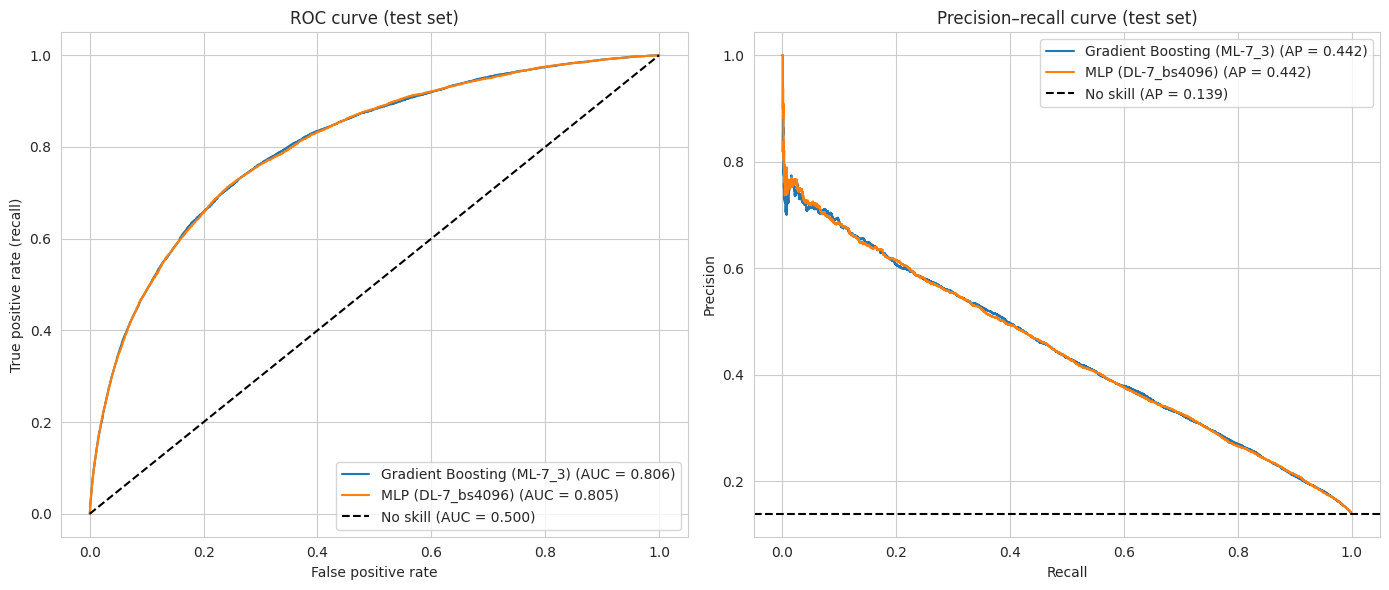

In [46]:
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for name, prob in test_probs.items():
    if name.startswith("Baseline"):
        continue
    fpr, tpr, _ = roc_curve(y_test, prob)
    prec, rec, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
    axes[1].plot(rec, prec, label=f"{name} (AP = {average_precision_score(y_test, prob):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", label="No skill (AUC = 0.500)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curve (test set)")
axes[0].legend(loc="lower right")

base_rate = y_test.mean()
axes[1].axhline(base_rate, color="k", linestyle="--", label=f"No skill (AP = {base_rate:.3f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–recall curve (test set)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig("figures/roc_pr_curves_test.png", dpi=150, bbox_inches="tight")
plt.show()

### Confusion matrices (test set, threshold 0.5)
A confusion matrix counts the four possible outcomes: people correctly identified as FMD (true positives), people correctly identified as not FMD (true negatives), false alarms (false positives), and missed cases (false negatives). The left matrix of each pair shows raw counts; the right matrix shows each row as a percentage of the true class, so the bottom row gives the share of real FMD cases that were found or missed.

Gradient Boosting (ML-7_3):  TP=6,763  FN=2,585  FP=14,914  TN=43,166   flagged=21,677 of 67,428
MLP (DL-7_bs4096):  TP=6,808  FN=2,540  FP=15,058  TN=43,022   flagged=21,866 of 67,428


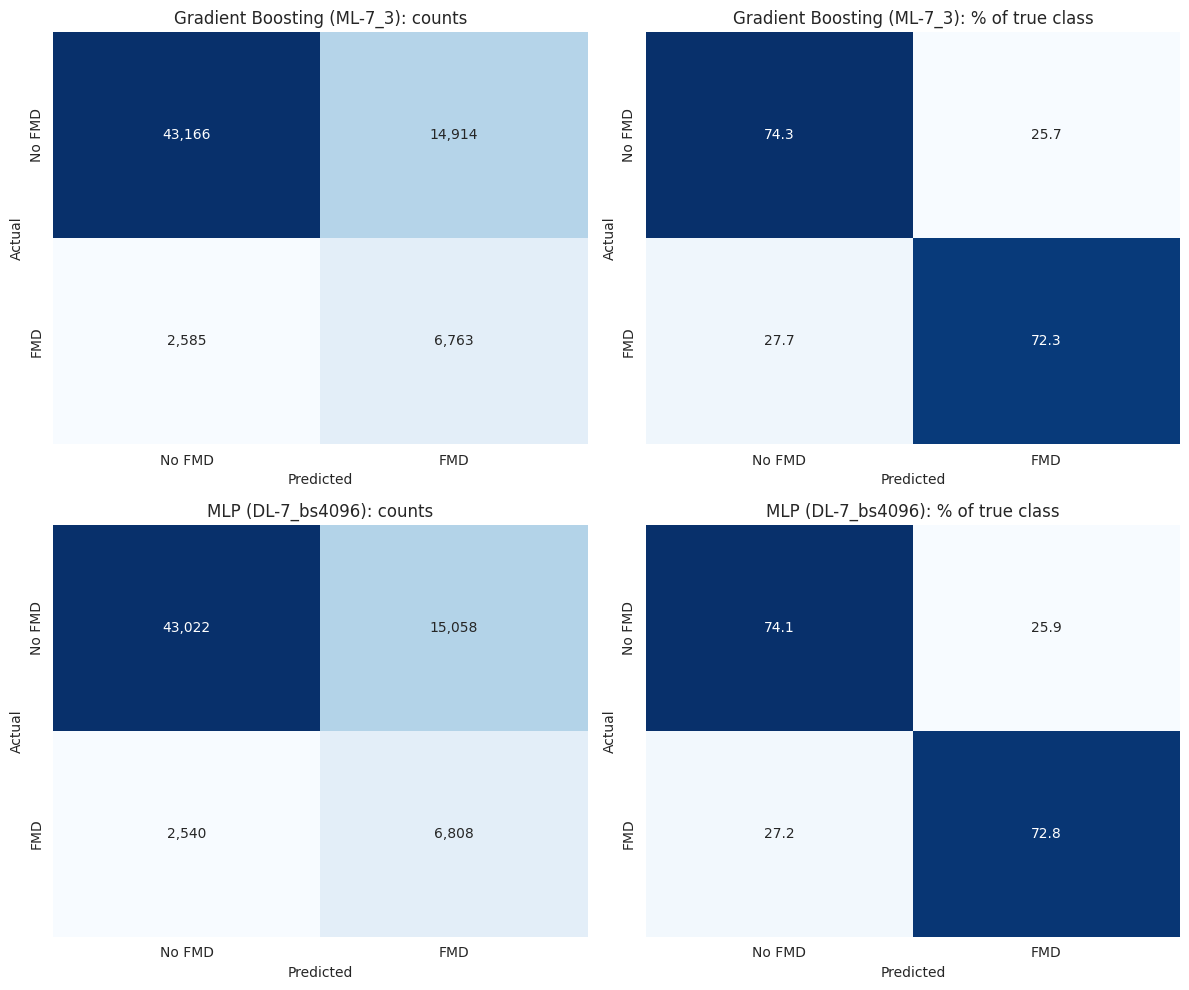

In [47]:
from sklearn.metrics import confusion_matrix

final_models = ["Gradient Boosting (ML-7_3)", "MLP (DL-7_bs4096)"]
labels = ["No FMD", "FMD"]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for row, name in enumerate(final_models):
    y_pred = (test_probs[name] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=axes[row, 0])
    axes[row, 0].set_title(f"{name}: counts")

    sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=axes[row, 1])
    axes[row, 1].set_title(f"{name}: % of true class")

    for ax in axes[row]:
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

    tn, fp, fn, tp = cm.ravel()
    print(f"{name}:  TP={tp:,}  FN={fn:,}  FP={fp:,}  TN={tn:,}   "
          f"flagged={tp + fp:,} of {len(y_test):,}")

plt.tight_layout()
plt.savefig("figures/confusion_matrices_test.png", dpi=150, bbox_inches="tight")
plt.show()

### Learning curves (deep learning)
Training and validation curves per epoch for three networks:
- **DL-3:** large network, no regularisation, stopped on validation loss.
- **DL-4:** large network with dropout and batch normalisation, stopped on validation loss (the run that revealed the early-stopping problem).
- **DL-7_bs4096:** the final model (L2 regularisation, stopped on validation AUC).

The top row shows ROC-AUC and the bottom row shows loss. Note that the training loss includes class weights while the validation loss does not, so the two loss curves are on different scales and their gap should not be read as overfitting. The AUC curves are directly comparable. The dotted vertical line marks the epoch whose weights were kept.

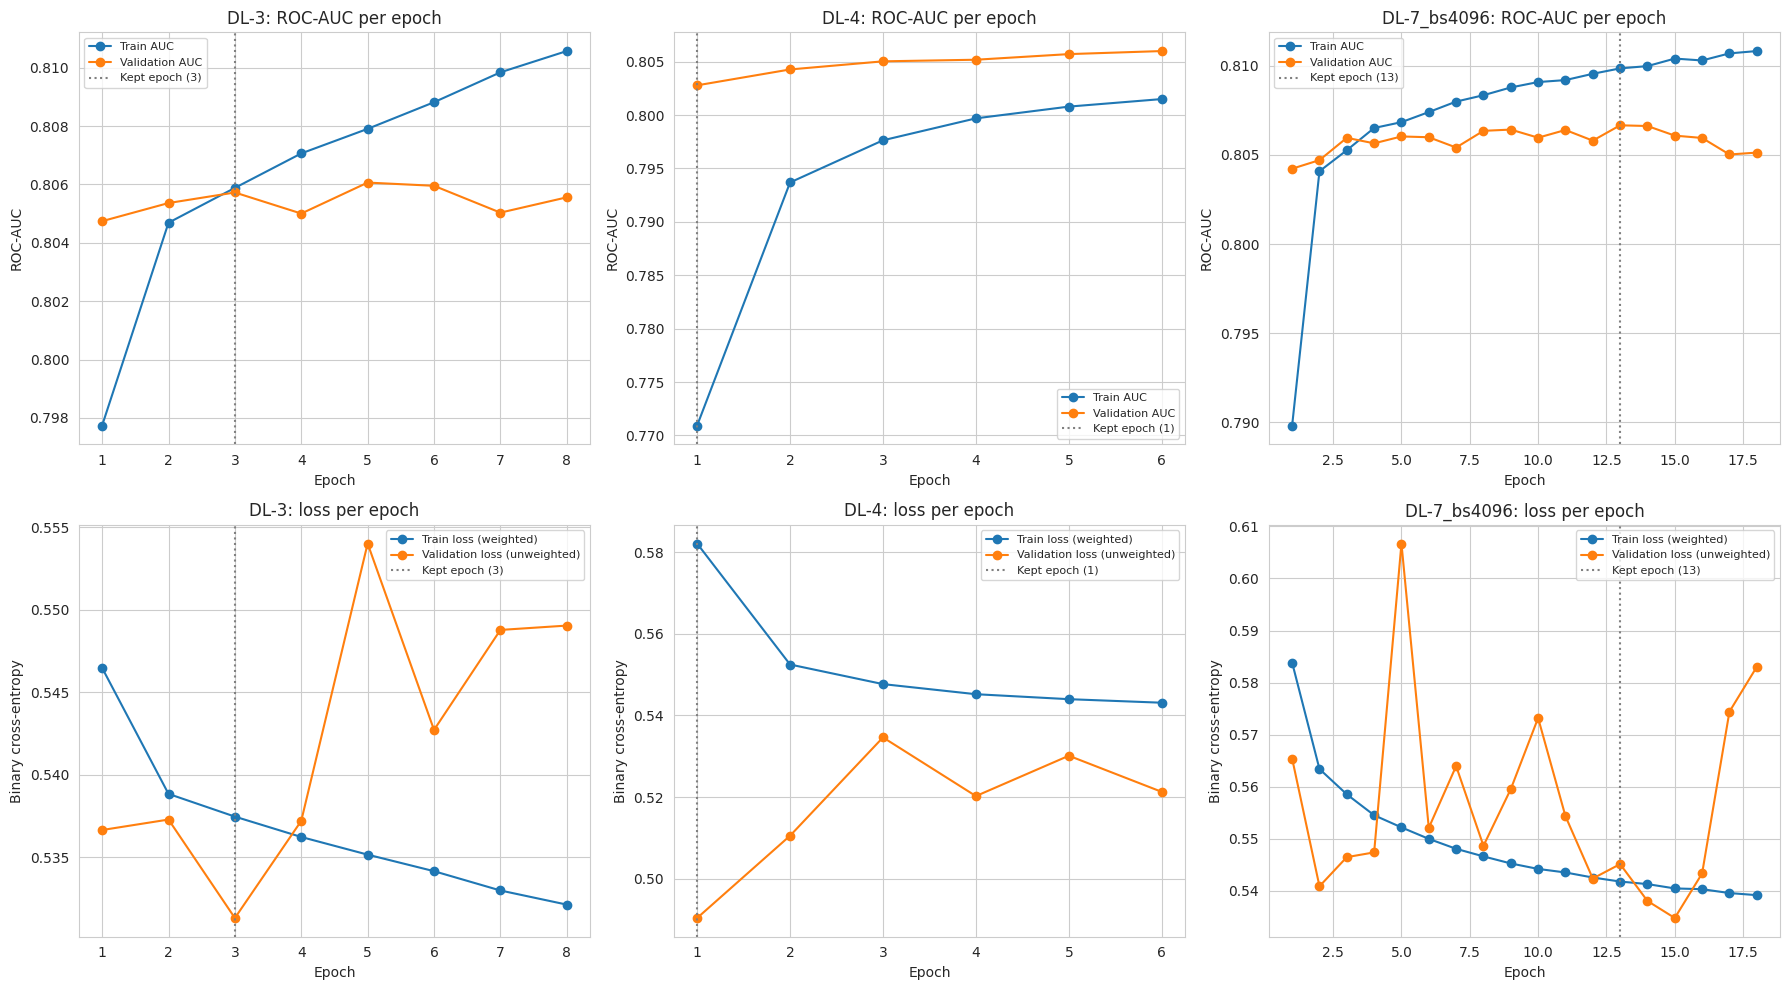

In [48]:
CURVE_RUNS = ["DL-3", "DL-4", "DL-7_bs4096"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for col, run_id in enumerate(CURVE_RUNS):
    h = DL_HISTORY[run_id]
    epochs = range(1, len(h["loss"]) + 1)
    params = json.loads(val_lookup.loc[run_id, "params"]) if run_id in val_lookup.index \
             else json.loads(pd.DataFrame(EXPERIMENTS).set_index("run_id").loc[run_id, "params"])
    best_ep = params.get("best_epoch")

    axes[0, col].plot(epochs, h["auc"], marker="o", label="Train AUC")
    axes[0, col].plot(epochs, h["val_auc"], marker="o", label="Validation AUC")
    axes[0, col].set_title(f"{run_id}: ROC-AUC per epoch")
    axes[0, col].set_xlabel("Epoch")
    axes[0, col].set_ylabel("ROC-AUC")

    axes[1, col].plot(epochs, h["loss"], marker="o", label="Train loss (weighted)")
    axes[1, col].plot(epochs, h["val_loss"], marker="o", label="Validation loss (unweighted)")
    axes[1, col].set_title(f"{run_id}: loss per epoch")
    axes[1, col].set_xlabel("Epoch")
    axes[1, col].set_ylabel("Binary cross-entropy")

    for ax in axes[:, col]:
        if best_ep:
            ax.axvline(best_ep, color="grey", linestyle=":", label=f"Kept epoch ({best_ep})")
        ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("figures/dl_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Learning curve over training-set size (gradient boosting)
The best traditional configuration (ML-7_3) is retrained on increasing fractions of the training set (1% to 100%, stratified samples), and ROC-AUC is measured on that training sample and on the full validation set. If validation ROC-AUC keeps rising with more data, the model is data-limited (high variance). If training and validation curves converge and flatten, more data would not help and performance is limited by bias, meaning by the information the features carry.

 fraction  train_rows  train_roc_auc  val_roc_auc
     0.01        3146         0.9449       0.7608
     0.05       15732         0.8265       0.7959
     0.10       31465         0.8248       0.8004
     0.25       78664         0.8147       0.8034
     0.50      157329         0.8114       0.8054
     1.00      314659         0.8093       0.8067


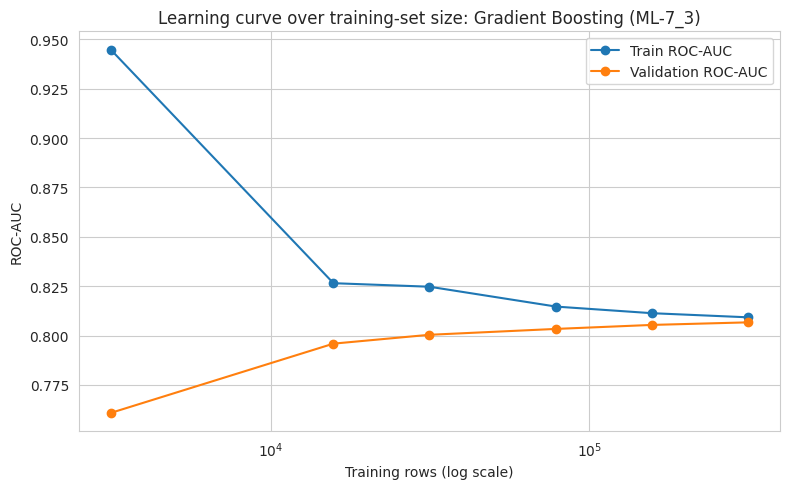

In [49]:
FRACTIONS = [0.01, 0.05, 0.10, 0.25, 0.50, 1.00]
size_rows = []

for frac in FRACTIONS:
    if frac < 1.0:
        X_sub, _, y_sub, _ = train_test_split(X_train_p, y_train, train_size=frac,
                                              stratify=y_train, random_state=SEED)
    else:
        X_sub, y_sub = X_train_p, y_train

    m = HistGradientBoostingClassifier(**BEST_GB, class_weight="balanced", random_state=SEED)
    m.fit(X_sub, y_sub)

    size_rows.append({
        "fraction": frac,
        "train_rows": len(y_sub),
        "train_roc_auc": roc_auc_score(y_sub, m.predict_proba(X_sub)[:, 1]),
        "val_roc_auc": roc_auc_score(y_val, m.predict_proba(X_val_p)[:, 1]),
    })

size_curve = pd.DataFrame(size_rows)
print(size_curve.round(4).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.plot(size_curve["train_rows"], size_curve["train_roc_auc"], marker="o", label="Train ROC-AUC")
plt.plot(size_curve["train_rows"], size_curve["val_roc_auc"], marker="o", label="Validation ROC-AUC")
plt.xscale("log")
plt.xlabel("Training rows (log scale)")
plt.ylabel("ROC-AUC")
plt.title("Learning curve over training-set size: Gradient Boosting (ML-7_3)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/gb_learning_curve_size.png", dpi=150, bbox_inches="tight")
plt.show()

### Threshold analysis
A model outputs a probability; the threshold decides when that probability counts as "FMD". Lowering it finds more people with FMD (higher recall) but creates more false alarms (lower precision); raising it does the opposite. The trade-off is examined for the final gradient boosting model on the **validation set**, since choosing a threshold is a tuning decision. The threshold that maximises F1-score on validation is then applied once to the test set.

 threshold  recall  precision    f1  flagged_%
      0.20   0.952      0.181 0.304     72.978
      0.25   0.921      0.201 0.331     63.374
      0.30   0.887      0.221 0.354     55.642
      0.35   0.850      0.242 0.377     48.679
      0.40   0.811      0.264 0.398     42.646
      0.45   0.769      0.286 0.417     37.224
      0.50   0.724      0.312 0.436     32.202
      0.55   0.681      0.339 0.452     27.879
      0.60   0.624      0.368 0.463     23.488
      0.65   0.563      0.400 0.468     19.495
      0.70   0.492      0.437 0.463     15.581
      0.75   0.411      0.480 0.443     11.875
      0.80   0.324      0.534 0.403      8.414

Best F1 threshold on validation: 0.65
Test at 0.5:      recall=0.723  precision=0.312  f1=0.436
Test at 0.65:     recall=0.557  precision=0.401  f1=0.466


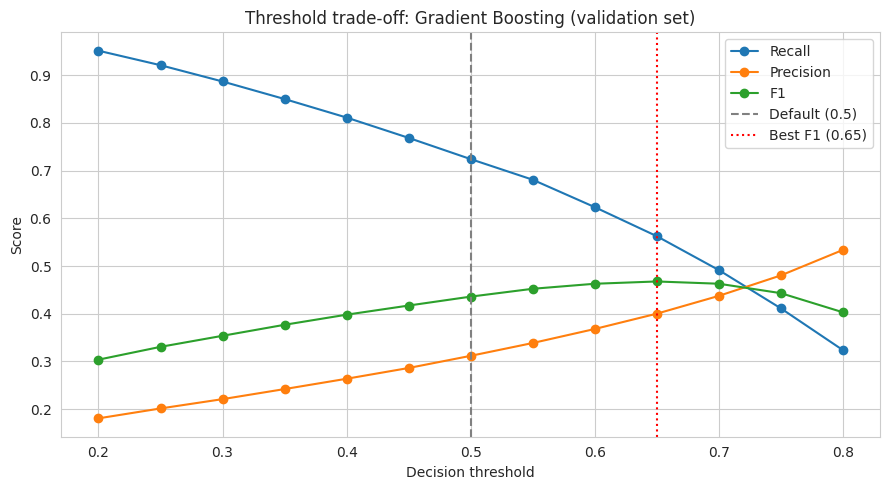

In [50]:
val_prob_gb = best_ml_model.predict_proba(X_val_p)[:, 1]

thresholds = np.round(np.arange(0.20, 0.81, 0.05), 2)
thr_rows = []
for t in thresholds:
    m = evaluate(y_val, val_prob_gb, threshold=t)
    thr_rows.append({"threshold": t, "recall": m["recall"], "precision": m["precision"],
                     "f1": m["f1"], "flagged_%": (val_prob_gb >= t).mean() * 100})

thr_table = pd.DataFrame(thr_rows)
print(thr_table.round(3).to_string(index=False))

best_t = thr_table.loc[thr_table["f1"].idxmax(), "threshold"]
print(f"\nBest F1 threshold on validation: {best_t}")

test_at_best = evaluate(y_test, test_probs["Gradient Boosting (ML-7_3)"], threshold=best_t)
test_at_05   = evaluate(y_test, test_probs["Gradient Boosting (ML-7_3)"], threshold=0.5)
print(f"Test at 0.5:      recall={test_at_05['recall']:.3f}  precision={test_at_05['precision']:.3f}  f1={test_at_05['f1']:.3f}")
print(f"Test at {best_t}:     recall={test_at_best['recall']:.3f}  precision={test_at_best['precision']:.3f}  f1={test_at_best['f1']:.3f}")

plt.figure(figsize=(9, 5))
plt.plot(thr_table["threshold"], thr_table["recall"], marker="o", label="Recall")
plt.plot(thr_table["threshold"], thr_table["precision"], marker="o", label="Precision")
plt.plot(thr_table["threshold"], thr_table["f1"], marker="o", label="F1")
plt.axvline(0.5, color="grey", linestyle="--", label="Default (0.5)")
plt.axvline(best_t, color="red", linestyle=":", label=f"Best F1 ({best_t})")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Threshold trade-off: Gradient Boosting (validation set)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/threshold_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

### Error analysis: performance across groups
The final gradient boosting model (threshold 0.5) is evaluated separately for each age group, for each sex, and for each income group on the test set. Differences in recall, precision, or ROC-AUC between groups would show where the model is less reliable, which matters for fairness and for the project's focus on young adults aged 18–24.

In [51]:
gb_test_prob = test_probs["Gradient Boosting (ML-7_3)"]
gb_test_pred = (gb_test_prob >= 0.5).astype(int)

def group_report(col, labels=None):
    rows = []
    for g in sorted(X_test[col].dropna().unique()):
        mask = (X_test[col] == g).values
        yt, yp, pr = y_test.values[mask], gb_test_pred[mask], gb_test_prob[mask]
        rows.append({
            col: labels.get(g, g) if labels else g,
            "n": mask.sum(),
            "FMD_rate_%": yt.mean() * 100,
            "recall": recall_score(yt, yp),
            "precision": precision_score(yt, yp, zero_division=0),
            "roc_auc": roc_auc_score(yt, pr),
            "flagged_%": yp.mean() * 100,
        })
    return pd.DataFrame(rows).round(3)

AGE_LABELS = {1: "18-24", 2: "25-29", 3: "30-34", 4: "35-39", 5: "40-44", 6: "45-49",
              7: "50-54", 8: "55-59", 9: "60-64", 10: "65-69", 11: "70-74", 12: "75-79", 13: "80+"}
SEX_LABELS = {1: "Male", 2: "Female"}

print("By age group:")
print(group_report("_AGEG5YR", AGE_LABELS).to_string(index=False))
print("\nBy sex:")
print(group_report("_SEX", SEX_LABELS).to_string(index=False))
print("\nBy income group (1 = lowest, 7 = highest):")
print(group_report("_INCOMG1").to_string(index=False))

By age group:
_AGEG5YR    n  FMD_rate_%  recall  precision  roc_auc  flagged_%
   18-24 4429      21.517   0.823      0.308    0.747     57.394
   25-29 3521      20.449   0.810      0.315    0.767     52.570
   30-34 3960      18.737   0.817      0.306    0.780     49.949
   35-39 4286      18.292   0.778      0.319    0.783     44.680
   40-44 4591      17.077   0.774      0.309    0.782     42.845
   45-49 4270      17.283   0.770      0.329    0.797     40.422
   50-54 4751      16.712   0.717      0.349    0.796     34.309
   55-59 5201      15.093   0.752      0.337    0.813     33.686
   60-64 6434      13.631   0.677      0.331    0.809     27.852
   65-69 6887       9.191   0.652      0.305    0.828     19.646
   70-74 6668       8.953   0.593      0.290    0.808     18.311
   75-79 5335       8.097   0.572      0.266    0.781     17.432
     80+ 5886       6.405   0.427      0.213    0.753     12.827

By sex:
  _SEX     n  FMD_rate_%  recall  precision  roc_auc  flagged_%
  M

### Error analysis: who is missed?
Among people who really have FMD, those the model found (true positives) are compared with those it missed (false negatives), using the raw survey answers. This shows what kind of person with frequent mental distress the model fails to recognise.

In [52]:
fmd_mask = (y_test == 1).values
tp_mask = fmd_mask & (gb_test_pred == 1)
fn_mask = fmd_mask & (gb_test_pred == 0)

profile_cols = {
    "_AGEG5YR": "Age group code (1 = 18-24)",
    "_INCOMG1": "Income group (1 = lowest)",
    "GENHLTH":  "General health (1 = excellent, 5 = poor)",
    "PHYSHLTH": "Poor physical-health days",
    "_BMI5":    "BMI",
}

prof = pd.DataFrame({
    "Found (TP)":  X_test.loc[tp_mask, list(profile_cols)].mean(),
    "Missed (FN)": X_test.loc[fn_mask, list(profile_cols)].mean(),
}).rename(index=profile_cols).round(2)

share = lambda col, val: [((X_test.loc[m, col] == val).mean() * 100).round(1) for m in (tp_mask, fn_mask)]
extra = pd.DataFrame({
    "Unable to work (%)":           share("EMPLOY1", 8),
    "Couldn't afford doctor (%)":   share("MEDCOST1", 1),
    "No exercise (%)":              share("EXERANY2", 2),
    "Daily smoker (%)":             share("_SMOKER3", 1),
    "Employed for wages (%)":       share("EMPLOY1", 1),
}, index=["Found (TP)", "Missed (FN)"]).T

print(f"People with FMD in test set: {fmd_mask.sum():,}   found: {tp_mask.sum():,}   missed: {fn_mask.sum():,}\n")
print(pd.concat([prof, extra]).to_string())

People with FMD in test set: 9,348   found: 6,763   missed: 2,585

                                          Found (TP)  Missed (FN)
Age group code (1 = 18-24)                      5.95         7.52
Income group (1 = lowest)                       3.61         4.76
General health (1 = excellent, 5 = poor)        3.65         2.46
Poor physical-health days                      14.90         1.71
BMI                                            30.38        28.35
Unable to work (%)                             21.90         2.50
Couldn't afford doctor (%)                     32.20         2.80
No exercise (%)                                38.80        21.00
Daily smoker (%)                               17.00         5.20
Employed for wages (%)                         37.60        46.00


## 13. Full Experiment Table
All 28 runs as recorded in `experiments.csv` and TensorBoard (`logs/`), in the order they were run. All metrics are on the validation set (split: 70/15/15 stratified, seed 42); full hyperparameters for each run are stored in the `params` column of `experiments.csv`.

In [53]:
full = pd.DataFrame(EXPERIMENTS)

show_cols = ["run_id", "model", "val_recall", "val_precision", "val_f1",
             "val_roc_auc", "val_pr_auc", "train_time_sec", "notes"]

pd.set_option("display.max_colwidth", 80)
display(full[show_cols])

,run_id,model,val_recall,val_precision,val_f1,val_roc_auc,val_pr_auc,train_time_sec,notes
0,ML-0,DummyClassifier,0.0000,0.0000,0.0000,0.5000,0.1386,0.0,Baseline: always predicts no FMD.
1,ML-1,LogisticRegression,0.1964,0.5924,0.2950,0.7995,0.4290,2.6,"First real model. Linear, no class weighting."
2,ML-2,LogisticRegression,0.6999,0.3122,0.4318,0.7998,0.4283,2.2,Same as ML-1 + class_weight='balanced' to raise recall on the minority class.
3,ML-3_C0.001,LogisticRegression,0.6998,0.3125,0.4320,0.7997,0.4279,1.8,ML-2 with C=0.001 (C=1.0 is ML-2). Tests regularisation strength.
4,ML-3_C0.01,LogisticRegression,0.7000,0.3124,0.4320,0.7998,0.4283,1.9,ML-2 with C=0.01 (C=1.0 is ML-2). Tests regularisation strength.
5,ML-3_C0.1,LogisticRegression,0.6998,0.3122,0.4318,0.7998,0.4283,2.6,ML-2 with C=0.1 (C=1.0 is ML-2). Tests regularisation strength.
6,ML-3_C10.0,LogisticRegression,0.6999,0.3122,0.4318,0.7998,0.4283,2.8,ML-2 with C=10.0 (C=1.0 is ML-2). Tests regularisation strength.
7,ML-4,RandomForestClassifier,0.1878,0.4915,0.2717,0.7684,0.3615,67.0,"Random Forest, full-depth trees. Tests non-linear model before tuning."
8,ML-5_d12_leaf100,RandomForestClassifier,0.7104,0.3129,0.4344,0.8011,0.4290,44.0,"ML-4 with max_depth=12, min_samples_leaf=100 to reduce overfitting."
9,ML-5_d20_leaf20,RandomForestClassifier,0.6888,0.3278,0.4442,0.8039,0.4344,56.4,"ML-4 with max_depth=20, min_samples_leaf=20 to reduce overfitting."


## 14. Results and Discussion

### Model comparison
| Model | Val ROC-AUC | Test ROC-AUC | Test PR-AUC | Test recall | Test precision | Test F1 | Train time |
|---|---|---|---|---|---|---|---|
| Majority baseline (ML-0) | 0.500 | 0.500 | 0.139 | 0.000 | 0.000 | 0.000 | 0 s |
| Logistic Regression (ML-2) | 0.800 | – | – | – | – | – | 2 s |
| Gradient Boosting (ML-7_3) | 0.807 | **0.806** | **0.442** | 0.723 | 0.312 | 0.436 | 11 s |
| MLP (DL-7_bs4096) | 0.807 | 0.805 | 0.442 | 0.728 | 0.311 | 0.436 | 96 s |

On the untouched test set, the best traditional and deep learning models are effectively identical (ROC-AUC 0.806 vs 0.805, PR-AUC 0.442 for both). Test scores are within 0.0015 of validation scores, so tuning on the validation set did not lead to overfitting. Gradient boosting reaches the same performance as the neural network while training about nine times faster, which makes it the more practical choice for this tabular problem.

### Why every model converges to the same ceiling
Three independent pieces of evidence show that performance is limited by the information in the 14 survey features, not by the choice of model:
1. **Model choice barely matters.** Moving from logistic regression (0.800) to tuned gradient boosting (0.807) or a 50,000-parameter neural network (0.807) gains less than 0.01 ROC-AUC.
2. **More data barely helps.** In the training-size learning curve, doubling the training data from 50% to 100% (about 157,000 more people) raises validation ROC-AUC by only 0.0013, and the training and validation curves converge at about 0.807–0.809.
3. **More information helps a lot.** Adding a single informative feature (`ADDEPEV3`, prior depression diagnosis) raises ROC-AUC from 0.807 to 0.843, five times more than all the model tuning combined. This feature is excluded from the final models because it is close to circular for a screening tool.

### Bias and variance
The experiments show both failure modes and the balance between them. Logistic regression is limited by **bias**: changing its regularisation strength C across four orders of magnitude had no effect, so it was not overfitting, and it cannot represent non-linear patterns such as the U-shaped BMI effect. The full-depth random forest (ML-4) shows **high variance**: training ROC-AUC 1.000 against 0.768 on validation. Limiting tree size (ML-5) and using gradient boosting closed the gap to 0.002–0.04. The neural network learning curves show the same pattern: the unregularised large network (DL-3) opens a widening train–validation gap after epoch 3, while L2 regularisation keeps the final model's gap small. With all training data, the final models sit in a high-bias, low-variance state, which matches the converging training-size learning curve.

### Optimisation findings
- **Class weights** were the most important single change for usefulness: they raised recall from about 0.20 to about 0.70 in both paradigms without changing ROC-AUC, showing that they move the decision boundary rather than improving how well the classes are separated.
- **Early stopping with class weights:** validation loss (computed without weights) was a misleading stopping signal, because it penalises the shift towards the minority class that class weights intentionally create. DL-4 stopped at its weakest epoch as a result. Monitoring validation ROC-AUC fixed this (DL-4: 0.803 → DL-4b: 0.807).
- **Regularisation:** dropout with batch normalisation and L2 both delayed overfitting (best epoch 5 → 13–14) and reached the same score; L2 trained about 35% faster.
- **Learning rate and batch size:** a learning rate of 0.01 was too large (earlier peak, lower score), while 0.001 and 0.0001 performed equally. Batch size (256 to 4,096) did not change performance but changed training time by more than half.
- **Feature engineering:** BMI categories gave the linear model a way to represent the U-shaped BMI effect. `INCOME_MISSING` did not help (ROC-AUC change −0.0003), which matches the small difference in FMD rate (13.0% vs 14.1%) found during feature engineering.

### Error analysis
**Threshold.** At the default threshold of 0.5, the gradient boosting model finds 72% of people with FMD but only 31% of the people it flags actually have FMD, and it flags about one in three people. Raising the threshold to 0.65 (the best F1 on validation) gives 56% recall and 40% precision on test and flags about one in five people. The right threshold depends on the cost of what follows a flag: a low-cost step such as sharing support resources can accept many false alarms, while a limited resource such as counsellor follow-up needs higher precision.

**Who is missed.** People with FMD whom the model misses look healthy on paper: on average they report 1.7 poor physical-health days (vs 14.9 for those found), better general health, higher income, and are much less often unable to work (2.5% vs 21.9%) or unable to afford a doctor (2.8% vs 32.2%). The model has learned that frequent mental distress usually appears together with physical illness and economic hardship, so it overlooks distress that appears without those signs.

**Differences between groups.** With a single threshold, recall follows each group's FMD rate: 0.91 for the lowest income group vs 0.40 for the highest, 0.76 for women vs 0.67 for men, and 0.82 for ages 18–24 vs 0.43 for ages 80+. Young adults have the highest recall, but the model flags 57% of them and has its **lowest ROC-AUC (0.747) in this group**, meaning it is weakest at telling which young adults actually have FMD. The strongest features describe physical health, employment, and income, which are less informative for young people, whose distress may come from factors this survey does not measure.

### Limitations
- The features cover physical health, lifestyle, and economic circumstances, but not sleep (not asked in 2024), loneliness, social support, academic or work stress, or past adverse experiences.
- BRFSS is a self-reported US telephone survey, so both the features and the target are subject to reporting bias, and results may not transfer to other countries, including Rwanda.
- The 2024 public release was modified, and some questions were removed, which reduced the available features.
- Survey sampling weights were not used, so the models describe the survey sample rather than the US adult population.
- The data is cross-sectional, so the models show associations, not causes.

### Future improvements
- Add features that capture mental and social life (sleep, loneliness, social support, stress), which the learning curves suggest would help far more than more data or larger models.
- Use group-specific thresholds or recalibration to reduce recall gaps between groups, while weighing the fairness trade-offs of treating groups differently.
- For a youth-focused tool, build or use datasets designed for young people, since the current model is least reliable for 18–24 year-olds.
- Apply the survey weights and test the model on other survey years to check stability.

## 15. Conclusion
This project predicted frequent mental distress (14 or more poor mental-health days in the past month) from 14 lifestyle, social, and physical-health features in the 2024 BRFSS survey (449,514 adults). Across 28 logged experiments, the best traditional model (gradient boosting) and the best deep learning model (a multi-layer perceptron with L2 regularisation) reached the same test performance (ROC-AUC 0.806 and 0.805, PR-AUC 0.442), finding about 72% of people with frequent mental distress at the default threshold. Gradient boosting reached this result about nine times faster.

The main finding is that performance is limited by what the survey measures, not by the model: model choice, model size, and more data all made little difference, while one additional informative feature improved results substantially. Error analysis showed that the model misses people whose distress is not accompanied by physical illness or economic hardship, and that it is least able to tell apart young adults with and without frequent mental distress, the group with the highest rate (21.4%). A screening tool built on these features could help direct support towards people facing visible hardship, but reaching young people, and people whose distress is less visible, would need richer information about mental and social well-being.

**Backing up outputs to Google Drive**

Colab's temporary storage is wiped when the session ends, so the experiment logs, saved models, figures, and experiment table are copied to Google Drive. This cell is only needed when running the notebook in Colab, and it asks for permission to access Drive.

In [54]:
from google.colab import drive
import shutil

drive.mount("/content/drive")

BACKUP_DIR = "/content/drive/MyDrive/FMD_project_backup"
os.makedirs(BACKUP_DIR, exist_ok=True)

for folder in ["logs", "models", "figures"]:
    shutil.copytree(folder, os.path.join(BACKUP_DIR, folder), dirs_exist_ok=True)
shutil.copy("experiments.csv", BACKUP_DIR)
shutil.copy("test_results.csv", BACKUP_DIR)

print("Backed up to:", BACKUP_DIR)
print(os.listdir(BACKUP_DIR))
print("Experiments in table:", len(EXPERIMENTS))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Backed up to: /content/drive/MyDrive/FMD_project_backup
['logs', 'models', 'figures', 'experiments.csv', 'test_results.csv']
Experiments in table: 28
